# Predicción de biodegradabilidad de sustancias químicas

**Proyecto integrador**
Machine Learning e Inferencia Bayesiana

El proyecto estudia la clasificación de sustancias químicas según su biodegradabilidad mediante
cinco algoritmos de aprendizaje supervisado. El análisis relaciona descriptores moleculares con
etiquetas experimentales y compara el desempeño de los clasificadores mediante métricas de evaluación.


## 1. Introducción

La biodegradabilidad es la capacidad de una sustancia para transformarse por la actividad de
microorganismos. Su estudio ayuda a comprender qué puede ocurrir con los compuestos que llegan
al ambiente. La clasificación depende de las condiciones y criterios de los ensayos: no es una
garantía universal de cómo se comportará una sustancia en cualquier ecosistema.

El análisis se basó en descriptores moleculares ya calculados para estudiar la relación
entre las características de las moléculas y su etiqueta experimental. El aprendizaje automático
puede apoyar el análisis y la comparación de sustancias; los resultados no sustituyen ensayos
experimentales ni una evaluación ambiental.

**Pregunta de investigación:** ¿cuál de cinco modelos clásicos de Machine Learning clasifica
mejor la biodegradabilidad de sustancias químicas a partir de sus descriptores moleculares?
Se estableció como criterio de comparación el mayor F1 de RB en validación cruzada de entrenamiento.

## 2. Objetivos

**Objetivo general:** comparar cinco algoritmos clásicos de clasificación supervisada para
predecir si una sustancia es fácilmente biodegradable a partir de sus características moleculares.

**Objetivos específicos:**

1. Verificar la estructura, calidad y significado de las variables del archivo original.
2. Preparar los datos y explorar sus distribuciones y asociaciones con gráficos sencillos.
3. Entrenar Regresión Logística, KNN, SVM, Gaussian Naive Bayes y Random Forest en los mismos datos.
4. Comparar los modelos mediante validación cruzada estratificada y evaluar sus predicciones finales.
5. Seleccionar un modelo justificando su rendimiento, sus limitaciones y sus fundamentos matemáticos.

## 3. Descripción del dataset

La fuente es [QSAR biodegradation](https://archive.ics.uci.edu/dataset/254/qsar+biodegradation), obtenida en UCI Machine Learning Repository.
La documentación describe **1,055 observaciones, 41 predictores y una clase**.
Se verificó estas cantidades permitiendo determinar el tamaño de la muestra tras la limpieza.
Las columnas no identifican las sustancias por nombre: son medidas numéricas enteras o reales
de composición, grupos funcionales y estructura molecular. Ejemplificados en la siguiente tabla:

| Descriptor | Interpretación sencilla |
|---|---|
| `nO` | Número de átomos de oxígeno |
| `nN` | Número de átomos de nitrógeno |
| `nX` | Número de átomos de halógenos |
| `C%` | Porcentaje de átomos de carbono; no es porcentaje en masa |
| `nHDon` | Número de átomos donadores de enlaces de hidrógeno (N y O) |

El resto incluye conteos de fragmentos y combinaciones matemáticas de la estructura molecular.
Los valores ya están incluidos en el archivo y se emplearon directamente como entradas de los clasificadores.
La lista de nombres de los descriptores moleculares y de la clase experimental se encuentran en la sección **Additional Variable Information** en UCI.

La etiqueta **RB** indica fácilmente biodegradable (*Ready Biodegradable*);
**NRB**, no clasificada como fácilmente biodegradable (*Not Ready Biodegradable*).
NRB no significa que la sustancia jamás pueda biodegradarse.
Se trata de clasificación binaria supervisada porque cada observación tiene una etiqueta experimental
y el objetivo es asignar una de dos categorías, en lugar de predecir una cantidad continua con metodos de regresión.

## 4. Carga y revisión inicial

El archivo utiliza `;` como separador, en vez de comas `,` , y no contiene encabezados declarados. La revisión inicial comprobó sus dimensiones, los tipos de datos, las clases, los valores faltantes, los duplicados y las posibles etiquetas contradictorias. Los nombres oficiales se asignaron según el orden de UCI.

In [5]:
from pathlib import Path
from time import perf_counter
import hashlib
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    make_scorer, confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.utils.validation import check_is_fitted

SEMILLA = 42
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 11})
pd.set_option("display.max_columns", 12)


In [6]:
# Orden de los descriptores verificado en la lista numerada oficial de UCI.
descriptores = [
    "SpMax_L", "J_Dz(e)", "nHM", "F01[N-N]", "F04[C-N]",
    "NssssC", "nCb-", "C%", "nCp", "nO", "F03[C-N]", "SdssC",
    "HyWi_B(m)", "LOC", "SM6_L", "F03[C-O]", "Me", "Mi", "nN-N",
    "nArNO2", "nCRX3", "SpPosA_B(p)", "nCIR", "B01[C-Br]",
    "B03[C-Cl]", "N-073", "SpMax_A", "Psi_i_1d", "B04[C-Br]",
    "SdO", "TI2_L", "nCrt", "C-026", "F02[C-N]", "nHDon",
    "SpMax_B(m)", "Psi_i_A", "nN", "SM6_B(m)", "nArCOOR", "nX",
]
assert len(descriptores) == 41 and len(set(descriptores)) == 41

ruta_csv = Path("data") / "raw" / "biodeg.csv"
if not ruta_csv.is_file():
    raise FileNotFoundError("Abra el notebook desde la raíz: falta data/raw/biodeg.csv.")
huella_original = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
datos_originales = pd.read_csv(ruta_csv, sep=";", header=None)
if datos_originales.shape != (1055, 42):
    raise ValueError(f"Estructura inesperada: {datos_originales.shape}; revisar antes de continuar.")
datos_originales.columns = descriptores + ["clase"]
display(datos_originales.head())

,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,...,Psi_i_A,nN,SM6_B(m),nArCOOR,nX,clase
0,3.919,2.6909,0,0,0,0,...,1.591,0,7.253,0,0,RB
1,4.170,2.1144,0,0,0,0,...,1.967,0,7.257,0,0,RB
2,3.932,3.2512,0,0,0,0,...,2.417,0,7.601,0,0,RB
3,3.000,2.7098,0,0,0,0,...,5.000,0,6.690,0,0,RB
4,4.236,3.3944,0,0,0,0,...,2.405,0,8.003,0,0,RB


In [7]:
# Detección de valores no numéricos antes de cualquier imputación o escalado.
entradas_numericas = datos_originales[descriptores].apply(pd.to_numeric, errors="coerce")
no_numericos = (
    entradas_numericas.isna() & datos_originales[descriptores].notna()
).sum().sum()
faltantes = int(datos_originales.isna().sum().sum())
duplicados_exactos = int(datos_originales.duplicated().sum())

# Mismos 41 valores numéricos pero más de una etiqueta: conflicto que exige revisión.
revision = entradas_numericas.assign(clase=datos_originales["clase"])
clases_por_entrada = revision.groupby(descriptores, dropna=False)["clase"].nunique()
conflictos = clases_por_entrada[clases_por_entrada > 1]

display(pd.Series({
    "Registros": len(datos_originales), "Predictores": len(descriptores),
    "Columnas totales": datos_originales.shape[1], "Valores faltantes": faltantes,
    "Duplicados exactos redundantes": duplicados_exactos,
    "Valores no numéricos inesperados": int(no_numericos),
    "Entradas con etiquetas contradictorias": len(conflictos),
}, name="Auditoría").to_frame())

display(pd.DataFrame({
    "posición (1 a 42)": range(1, 43),
    "nombre": datos_originales.columns,
    "tipo leído": datos_originales.dtypes.astype(str).to_numpy(),
    "faltantes": datos_originales.isna().sum().to_numpy(),
}))
conteos_originales = datos_originales["clase"].value_counts().reindex(["NRB", "RB"])
display(pd.DataFrame({
    "registros": conteos_originales,
    "porcentaje": 100 * conteos_originales / len(datos_originales),
}).round(2))
print("Filas que participan en grupos de duplicados exactos:")
display(datos_originales.loc[datos_originales.duplicated(keep=False)])

if set(datos_originales["clase"].unique()) != {"RB", "NRB"}:
    raise ValueError("Etiquetas inesperadas: se requiere revisar el CSV.")
if len(conflictos):
    display(conflictos)
    raise ValueError("Hay entradas con etiquetas contradictorias. Consultar antes de tratarlas.")
if no_numericos or faltantes or not np.isfinite(entradas_numericas.to_numpy()).all():
    raise ValueError("Hay valores inválidos o faltantes: revisar el tratamiento antes de continuar.")

,Auditoría
Registros,1055
Predictores,41
Columnas totales,42
Valores faltantes,0
Duplicados exactos redundantes,3
Valores no numéricos inesperados,0
Entradas con etiquetas contradictorias,0


,posición (1 a 42),nombre,tipo leído,faltantes
0,1,SpMax_L,float64,0
1,2,J_Dz(e),float64,0
2,3,nHM,int64,0
3,4,F01[N-N],int64,0
4,5,F04[C-N],int64,0
5,6,NssssC,int64,0
6,7,nCb-,int64,0
7,8,C%,float64,0
8,9,nCp,int64,0
9,10,nO,int64,0


,registros,porcentaje
clase,,
NRB,699,66.26
RB,356,33.74


Filas que participan en grupos de duplicados exactos:


,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,...,Psi_i_A,nN,SM6_B(m),nArCOOR,nX,clase
132,4.343,3.9399,0,0,0,0,...,4.167,0,8.016,0,0,RB
178,4.983,4.2631,0,0,0,0,...,3.694,0,7.880,0,0,RB
196,4.343,3.9399,0,0,0,0,...,4.167,0,8.016,0,0,RB
268,4.983,4.2631,0,0,0,0,...,3.694,0,7.880,0,0,RB
299,5.998,1.8789,6,0,0,3,...,2.355,0,9.843,0,6,NRB
910,5.998,1.8789,6,0,0,3,...,2.355,0,9.843,0,6,NRB


## 5. Limpieza y preprocesamiento

Se eliminaron únicamente las repeticiones exactas de las 42 columnas, conservando una copia.
Son redundantes para este análisis por observación: el CSV no incluye identificadores que
permitan reconocerlas como ensayos independientes. Esta decisión evita que una copia idéntica
llegue a entrenamiento y otra a prueba. No implica que todos los compuestos químicamente
relacionados queden separados.

Las clases se codificaron como **RB = 1** y **NRB = 0**; esta numeración permite calcular métricas de RB como clase positiva y NRB como clase negativa.
Se conservaron los **41 predictores** y no se eliminaron valores extremos automáticamente.

El preprocesamiento se definió antes de evaluar los modelos:

| Modelos | Preprocesamiento | Motivo |
|---|---|---|
| Regresión Logística, KNN y SVM | `StandardScaler` dentro de cada `Pipeline` | Evitar que unidades y magnitudes dominen distancias o regularización |
| Gaussian Naive Bayes | Valores numéricos originales | Estima una media y una varianza por variable y clase; no requiere distancias comparables |
| Random Forest | Valores numéricos originales | Las divisiones de los árboles no necesitan estandarización |

La estandarización ajusta los valores de cada variable restando su media y dividiendo entre su desviación estándar. Este proceso se realiza únicamente con los datos de entrenamiento y se repite en cada partición de la validación cruzada, evitando utilizar información de los datos de validación o prueba.

Los valores extremos se revisaron durante el análisis exploratorio (EDA), sin eliminarlos automáticamente.

In [8]:
datos = datos_originales.drop_duplicates().copy()
datos[descriptores] = entradas_numericas.loc[datos.index]
X = datos[descriptores].copy()
y = datos["clase"].map({"NRB": 0, "RB": 1}).astype(int)

display(Markdown(
    f"Se retiraron **{len(datos_originales) - len(datos)} copias redundantes** y quedaron "
    f"**{len(datos)} observaciones únicas**, con **{X.shape[1]} predictores**. "
    f"Se encontraron **{faltantes} valores faltantes**: no fue necesario imputar. "
    "No se eliminaron valores extremos ni variables, y no se modificó el archivo original."
))
display(datos["clase"].value_counts().reindex(["NRB", "RB"]).rename("Registros limpios").to_frame())

Se retiraron **3 copias redundantes** y quedaron **1052 observaciones únicas**, con **41 predictores**. Se encontraron **0 valores faltantes**: no fue necesario imputar. No se eliminaron valores extremos ni variables, y no se modificó el archivo original.

,Registros limpios
clase,
NRB,698
RB,354


## 6. Análisis exploratorio de datos (EDA)

Antes del análisis exploratorio (EDA), los datos se dividieron en 80% para entrenamiento y 20% para prueba. Las gráficas se realizaron únicamente con los datos de entrenamiento. Se seleccionaron algunas variables para visualizar sus características, pero los cinco modelos utilizaron los 41 descriptores disponibles.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA,
)
eda = X_train.copy()
eda["clase"] = y_train.map({0: "NRB", 1: "RB"})
variables_sencillas = ["nO", "nN", "C%"]

### Distribución de clases

Las alturas muestran cuántas observaciones hay por categoría en entrenamiento.
Una clase mayoritaria puede dar un accuracy aparentemente alto aunque se reconozcan pocas RB.
La tabla de la auditoría permite consultar también la distribución del archivo completo.

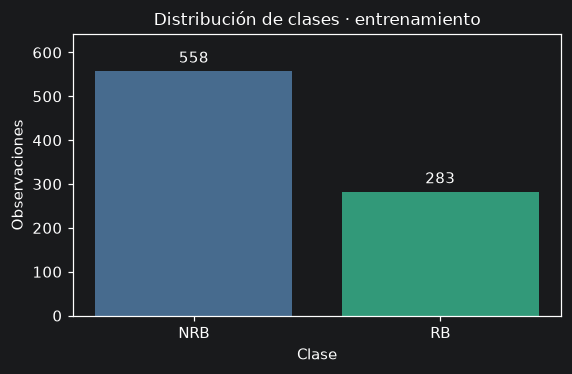

En entrenamiento, **NRB representa 66.3%** y **RB 33.7%**. Por ello se comparan precision, recall y F1 de RB, además de accuracy.

In [10]:
conteos_train = eda["clase"].value_counts().reindex(["NRB", "RB"])
fig, ax = plt.subplots(figsize=(5.3, 3.5))
barras = ax.bar(conteos_train.index, conteos_train.values, color=["#476b8e", "#329979"])
ax.bar_label(barras, padding=3)
ax.set(title="Distribución de clases · entrenamiento", xlabel="Clase", ylabel="Observaciones")
ax.set_ylim(0, conteos_train.max() * 1.15)
fig.tight_layout()
plt.show()
display(Markdown(
    f"En entrenamiento, **NRB representa {100 * (y_train == 0).mean():.1f}%** "
    f"y **RB {100 * y_train.mean():.1f}%**. Por ello se comparan precision, recall y F1 de RB, "
    "además de accuracy."
))

### Estadísticas descriptivas e histogramas

La tabla resume los 41 descriptores del entrenamiento: tamaño de muestra, media, desviación
estándar, mínimo, cuartiles y máximo. Un descriptor de conteo y uno porcentual pueden tener escalas
muy diferentes. Los histogramas muestran concentración, dispersión y posibles colas; no prueban
que una variable sea normal ni que una característica cause biodegradabilidad.

,count,mean,std,min,25%,50%,75%,max
SpMax_L,841.0,4.775,0.540,2.000,4.481,4.828,5.115,6.316
J_Dz(e),841.0,3.065,0.807,0.804,2.518,3.044,3.436,9.178
nHM,841.0,0.703,1.434,0.000,0.000,0.000,1.000,10.000
F01[N-N],841.0,0.038,0.241,0.000,0.000,0.000,0.000,3.000
F04[C-N],841.0,0.966,2.368,0.000,0.000,0.000,1.000,36.000
NssssC,841.0,0.263,0.970,0.000,0.000,0.000,0.000,12.000
nCb-,841.0,1.636,2.232,0.000,0.000,1.000,3.000,18.000
C%,841.0,37.015,9.176,0.000,30.400,37.500,42.900,60.700
nCp,841.0,1.384,1.996,0.000,0.000,1.000,2.000,24.000
nO,841.0,1.795,1.794,0.000,0.000,2.000,3.000,12.000


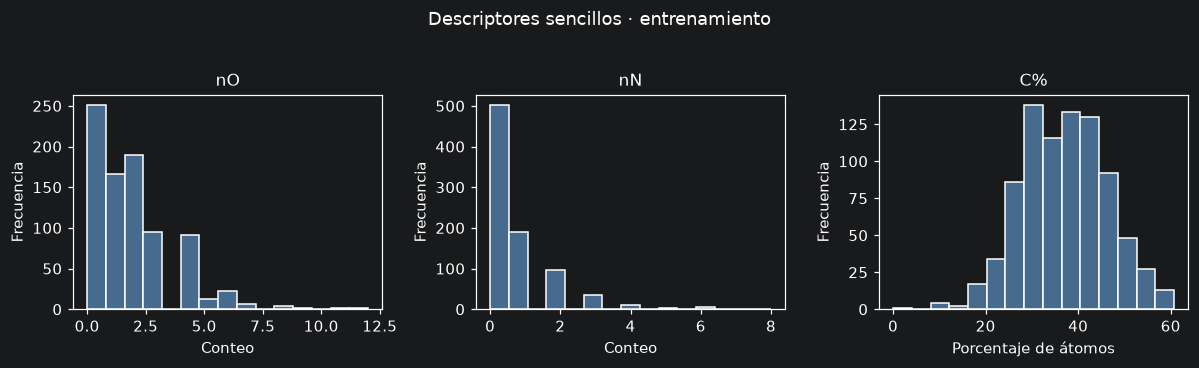

**nO:** mínimo 0.00, mediana 2.00, máximo 12.00; **29.8%** de valores iguales a cero. Estos resúmenes ayudan a interpretar la concentración y la amplitud del histograma.

**nN:** mínimo 0.00, mediana 0.00, máximo 8.00; **59.7%** de valores iguales a cero. Estos resúmenes ayudan a interpretar la concentración y la amplitud del histograma.

**C%:** mínimo 0.00, mediana 37.50, máximo 60.70; **0.1%** de valores iguales a cero. Estos resúmenes ayudan a interpretar la concentración y la amplitud del histograma.

In [11]:
display(X_train.describe().T.round(3))
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, variable in zip(ejes, variables_sencillas):
    ax.hist(X_train[variable], bins=15, color="#476b8e", edgecolor="white")
    ax.set(title=variable, xlabel="Porcentaje de átomos" if variable == "C%" else "Conteo", ylabel="Frecuencia")
fig.suptitle("Descriptores sencillos · entrenamiento", y=1.03)
fig.tight_layout()
plt.show()
for variable in variables_sencillas:
    serie = X_train[variable]
    display(Markdown(
        f"**{variable}:** mínimo {serie.min():.2f}, mediana {serie.median():.2f}, "
        f"máximo {serie.max():.2f}; **{100 * (serie == 0).mean():.1f}%** de valores iguales a cero. "
        "Estos resúmenes ayudan a interpretar la concentración y la amplitud del histograma."
    ))

### Boxplots por clase e inspección de extremos

La línea central de cada caja es la mediana; la caja abarca del primer al tercer cuartil.
Los puntos más allá de los bigotes son posibles extremos según la regla de 1.5 veces el rango
intercuartílico ($IQR=Q_3-Q_1$). Es una señal exploratoria, no una identificación de errores químicos.
Una diferencia entre cajas indica una asociación en esta muestra, no una explicación causal.

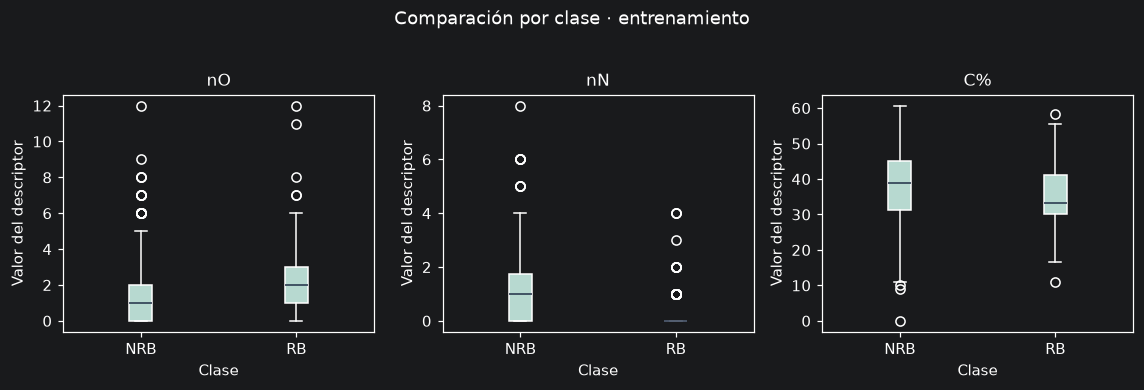

Medianas por clase (leer junto con el solapamiento de las cajas):


,nO,nN,C%
clase,,,
NRB,1.0,1.0,38.9
RB,2.0,0.0,33.3


,Valores fuera de la regla IQR
nO,8
nN,54
C%,5


Se conservan todos estos valores: un conteo molecular poco frecuente puede ser válido. Si el IQR es cero, esta regla puede marcar muchos valores de un descriptor discreto; por sí sola no justifica eliminar registros.

In [12]:
fig, ejes = plt.subplots(1, 3, figsize=(10.5, 3.4))
for ax, variable in zip(ejes, variables_sencillas):
    grupos = [eda.loc[eda["clase"] == clase, variable] for clase in ["NRB", "RB"]]
    ax.boxplot(grupos, tick_labels=["NRB", "RB"], patch_artist=True,
               boxprops={"facecolor": "#b7d9d0"}, medianprops={"color": "#202f46"})
    ax.set(title=variable, xlabel="Clase", ylabel="Valor del descriptor")
fig.suptitle("Comparación por clase · entrenamiento", y=1.03)
fig.tight_layout()
plt.show()

medianas = eda.groupby("clase")[variables_sencillas].median().reindex(["NRB", "RB"])
print("Medianas por clase (leer junto con el solapamiento de las cajas):")
display(medianas)
q1 = X_train[variables_sencillas].quantile(0.25)
q3 = X_train[variables_sencillas].quantile(0.75)
iqr = q3 - q1
posibles_extremos = (
    (X_train[variables_sencillas] < q1 - 1.5 * iqr)
    | (X_train[variables_sencillas] > q3 + 1.5 * iqr)
).sum()
display(posibles_extremos.rename("Valores fuera de la regla IQR").to_frame())
display(Markdown(
    "Se conservan todos estos valores: un conteo molecular poco frecuente puede ser válido. "
    "Si el IQR es cero, esta regla puede marcar muchos valores de un descriptor discreto; "
    "por sí sola no justifica eliminar registros."
))

### Correlaciones de un subconjunto

Se analizó un subconjunto de seis variables interpretables mediante la correlación de Pearson,
que resume la asociación lineal entre pares numéricos. Valores próximos a +1 o −1 indican asociaciones lineales más marcadas.
Un valor cercano a cero no descarta relaciones no lineales. La correlación no demuestra causalidad.
Este gráfico no se usa para seleccionar o quitar predictores.

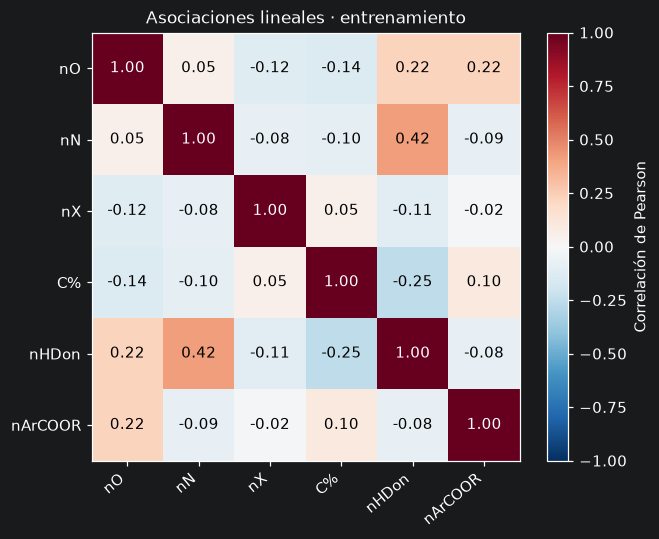

Entre los pares mostrados, **nN y nHDon** presentan la mayor correlación absoluta: **r = 0.42**. La asociación entre descriptores recuerda que la independencia condicional de Naive Bayes es una simplificación; este gráfico global tampoco es una prueba formal de ese supuesto.

In [13]:
variables_correlacion = ["nO", "nN", "nX", "C%", "nHDon", "nArCOOR"]
correlacion = X_train[variables_correlacion].corr()
fig, ax = plt.subplots(figsize=(6.2, 5))
imagen = ax.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(variables_correlacion)), variables_correlacion, rotation=40, ha="right")
ax.set_yticks(range(len(variables_correlacion)), variables_correlacion)
for i in range(len(variables_correlacion)):
    for j in range(len(variables_correlacion)):
        valor = correlacion.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center",
                color="white" if abs(valor) > 0.6 else "black")
fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")
ax.set_title("Asociaciones lineales · entrenamiento")
fig.tight_layout()
plt.show()
pares = correlacion.where(np.triu(np.ones(correlacion.shape), k=1).astype(bool)).stack()
par_mayor = pares.abs().idxmax()
display(Markdown(
    f"Entre los pares mostrados, **{par_mayor[0]} y {par_mayor[1]}** presentan la mayor "
    f"correlación absoluta: **r = {pares.loc[par_mayor]:.2f}**. "
    "La asociación entre descriptores recuerda que la independencia condicional de Naive Bayes "
    "es una simplificación; este gráfico global tampoco es una prueba formal de ese supuesto."
))

## 7. División de los datos

La llamada a `train_test_split` de la sección 6 reservó **20% para prueba y 80% para entrenamiento**,
con `stratify=y` y `random_state=42`. Los tamaños enteros pueden diferir levemente del porcentaje exacto.

- **Entrenamiento:** permite aprender parámetros, explorar los datos y comparar modelos mediante
  cinco particiones estratificadas internas.
- **Prueba:** permite estimar el rendimiento final en observaciones reservadas. Se consulta después
  de fijar el modelo seleccionado por validación cruzada y no se usa para reajustarlo.
- **Estratificación:** mantiene aproximadamente las proporciones de RB y NRB en cada conjunto.

El EDA no alteró las variables, el preprocesamiento ni las configuraciones ya previstas.
La estandarización se ajustó solo con entrenamiento y se mantuvo una única división durante el análisis.

In [14]:
resumen_division = pd.DataFrame({
    "observaciones": [len(y), len(y_train), len(y_test)],
    "NRB": [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    "RB": [(y == 1).sum(), (y_train == 1).sum(), (y_test == 1).sum()],
    "% RB": [100 * y.mean(), 100 * y_train.mean(), 100 * y_test.mean()],
}, index=["Total limpio", "Entrenamiento", "Prueba"])
display(resumen_division.round(2))
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(X)
# La ausencia de conflictos y de duplicados garantiza también ausencia de entradas idénticas.
assert not pd.concat([X_train, X_test]).duplicated().any()

,observaciones,NRB,RB,% RB
Total limpio,1052,698,354,33.65
Entrenamiento,841,558,283,33.65
Prueba,211,140,71,33.65


## 8. Modelado de Machine Learning

Se compararon cinco clasificadores con los mismos 41 predictores y las mismas observaciones
de entrenamiento. Las configuraciones se definieron antes de evaluar el conjunto de prueba.
Se emplearon valores básicos de los hiperparámetros, sin búsquedas de optimización,
ponderaciones de clase ni cambios de umbral.

### Modelo 1. Regresión Logística

Combina linealmente las características y aplica una sigmoide para estimar la probabilidad de RB.  
Permite interpretar el signo de los coeficientes y sirve como modelo de referencia comprensible.  
Se empleó regularización L2 predeterminada, `C=1` y el optimizador L-BFGS.  
El escalado se incluyó en el Pipeline y `max_iter=2000` se fijó como límite para permitir la convergencia.

In [15]:
modelos = {}
modelos["Regresión Logística"] = Pipeline([
    ("escala", StandardScaler()),
    ("clasificador", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000)),
])

### Modelo 2. K-Nearest Neighbors (KNN)

Para una observación nueva busca las cinco observaciones de entrenamiento más cercanas.  
La clase se decide por mayoría de esos vecinos, con igual peso para cada uno.  
Es intuitivo y permite explorar si moléculas cercanas en descriptores comparten etiqueta.  
Se emplearon la distancia euclidiana y el escalado dentro del Pipeline, porque las unidades afectan las distancias.

In [16]:
modelos["KNN"] = Pipeline([
    ("escala", StandardScaler()),
    ("clasificador", KNeighborsClassifier(n_neighbors=5, weights="uniform", p=2)),
])

### Modelo 3. Support Vector Machine (SVM)

Busca una frontera de separación con un margen amplio entre clases.  
El kernel RBF permite representar una frontera no lineal sin diseñarla manualmente.  
Es útil para comparar una separación flexible con la frontera lineal de Regresión Logística.  
Se fijaron `C=1`, `gamma="scale"` y escalado dentro del Pipeline; estos valores no se ajustaron con el test.

In [17]:
modelos["SVM"] = Pipeline([
    ("escala", StandardScaler()),
    ("clasificador", SVC(kernel="rbf", C=1.0, gamma="scale")),
])

### Modelo 4. Gaussian Naive Bayes

Aplica el teorema de Bayes y aproxima cada descriptor con una distribución normal dentro de cada clase.  
Supone independencia condicional de las variables, un supuesto simplificador que puede no cumplirse.  
Se incluye por su sencillez, rapidez y relación directa con Inferencia Bayesiana.  
Se conservaron las escalas originales, ya que estima medias y varianzas propias, con el suavizado de varianza predeterminado.

In [18]:
modelos["Gaussian Naive Bayes"] = Pipeline([
    ("clasificador", GaussianNB(var_smoothing=1e-9)),
])

### Modelo 5. Random Forest

Combina votos de árboles entrenados con muestras aleatorias del entrenamiento y subconjuntos de variables.  
Puede representar relaciones no lineales e interacciones sin estandarización.  
Es una comparación útil frente a métodos lineales, de distancia y probabilísticos.  
Se fijaron 100 árboles y semilla 42; su interpretación global es menos directa y también puede sobreajustar.

In [19]:
modelos["Random Forest"] = Pipeline([
    ("clasificador", RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=1)),
])

# Ajustes definitivos sobre TODO el entrenamiento; el test sigue reservado.
modelos_entrenados = {}
tiempos_entrenamiento = {}
for nombre, pipeline in modelos.items():
    modelo = clone(pipeline)
    inicio = perf_counter()
    modelo.fit(X_train, y_train)
    tiempos_entrenamiento[nombre] = perf_counter() - inicio
    modelos_entrenados[nombre] = modelo

display(pd.Series(tiempos_entrenamiento, name="Ajuste sobre entrenamiento (s)").to_frame().round(4))
print("Modelos ajustados:", len(modelos_entrenados))

,Ajuste sobre entrenamiento (s)
Regresión Logística,0.0120
KNN,0.0036
SVM,0.0168
Gaussian Naive Bayes,0.0022
Random Forest,0.1810


Modelos ajustados: 5


## 9. Evaluación

Se consideró **RB = 1** como clase positiva. **TP** son RB predichas RB; **TN**, NRB predichas NRB;
**FP**, NRB predichas RB; **FN**, RB predichas NRB.

| Métrica | Fórmula | Lectura sencilla |
|---|---|---|
| Accuracy | $(TP+TN)/(TP+TN+FP+FN)$ | De todas las predicciones, ¿qué fracción fue correcta? |
| Precision de RB | $TP/(TP+FP)$ | De las predichas como RB, ¿qué fracción era realmente RB? |
| Recall de RB | $TP/(TP+FN)$ | De todas las RB reales, ¿qué fracción se identificó? |
| F1 de RB | $2PR/(P+R)$ | Equilibra precision $P$ y recall $R$ mediante su media armónica |

**Ejemplo didáctico, no un resultado del dataset:** si de 10 predicciones RB aciertan 8, la precision
es 0.80. Si existían 16 RB reales y se identificaron 8, el recall es 0.50 y F1 es aproximadamente 0.62.
La matriz de confusión indica además los tipos concretos de error.

**Regla de selección previa:** mayor **F1 medio de RB** en cinco particiones estratificadas del
entrenamiento. Si hay igualdad exacta, se conserva el orden de presentación de los modelos.
Accuracy, precision y recall son complementarias. La desviación estándar de F1 describe variación
entre particiones; no es un intervalo de confianza ni una prueba de superioridad estadística.

In [20]:
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas_cv = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
}
filas_cv = []
f1_por_particion = {}
for nombre, pipeline in modelos.items():
    # cross_validate clona el Pipeline: ningún escalador ve su partición de validación.
    puntuaciones = cross_validate(
        pipeline, X_train, y_train, cv=validacion, scoring=metricas_cv,
        n_jobs=1, error_score="raise",
    )
    f1_por_particion[nombre] = puntuaciones["test_f1"]
    filas_cv.append({
        "Modelo": nombre,
        "Accuracy CV": puntuaciones["test_accuracy"].mean(),
        "Precision CV": puntuaciones["test_precision"].mean(),
        "Recall CV": puntuaciones["test_recall"].mean(),
        "F1 CV": puntuaciones["test_f1"].mean(),
        "DE F1 CV": puntuaciones["test_f1"].std(ddof=1),
    })
resultados_cv = pd.DataFrame(filas_cv).set_index("Modelo")
ranking_cv = resultados_cv.sort_values("F1 CV", ascending=False, kind="stable")
modelo_seleccionado = ranking_cv.index[0]  # Se fija ANTES de calcular métricas de prueba.
display(ranking_cv.round(4))
display(Markdown(
    f"**Seleccionado por validación cruzada: {modelo_seleccionado}.** "
    f"F1 medio = **{ranking_cv.iloc[0]['F1 CV']:.4f}**, "
    f"desviación estándar = **{ranking_cv.iloc[0]['DE F1 CV']:.4f}**. "
    "El nombre `test_f1` que devuelve scikit-learn se refiere aquí a las particiones internas "
    "de validación, no al conjunto de prueba reservado."
))

,Accuracy CV,Precision CV,Recall CV,F1 CV,DE F1 CV
Modelo,,,,,
SVM,0.8835,0.8539,0.7917,0.8211,0.0375
Regresión Logística,0.8799,0.8255,0.8164,0.8205,0.0231
Random Forest,0.8787,0.8530,0.7742,0.8109,0.0358
KNN,0.8538,0.7751,0.7987,0.7863,0.0384
Gaussian Naive Bayes,0.6766,0.5115,0.9506,0.6648,0.0222


**Seleccionado por validación cruzada: SVM.** F1 medio = **0.8211**, desviación estándar = **0.0375**. El nombre `test_f1` que devuelve scikit-learn se refiere aquí a las particiones internas de validación, no al conjunto de prueba reservado.

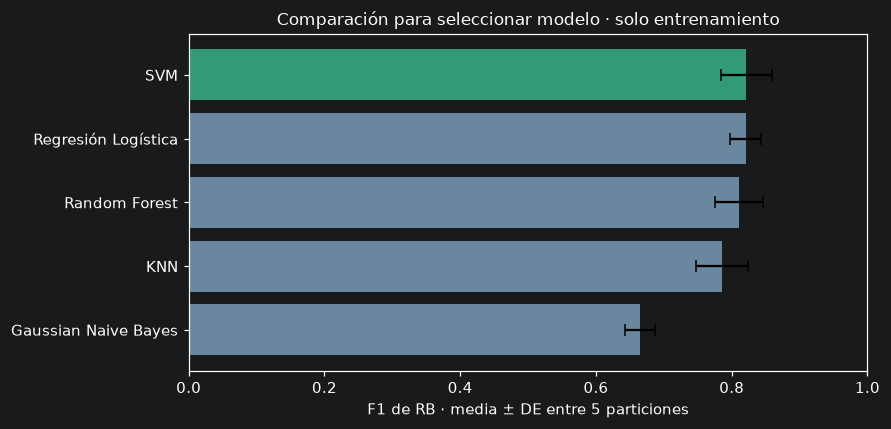

In [21]:
fig, ax = plt.subplots(figsize=(8.2, 4))
posiciones = np.arange(len(ranking_cv))
ax.barh(posiciones, ranking_cv["F1 CV"], xerr=ranking_cv["DE F1 CV"],
        color=["#329979"] + ["#6b879f"] * (len(ranking_cv) - 1), capsize=4)
ax.set_yticks(posiciones, ranking_cv.index)
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="F1 de RB · media ± DE entre 5 particiones",
       title="Comparación para seleccionar modelo · solo entrenamiento")
fig.tight_layout()
plt.show()

### Evaluación final en prueba

Después de seleccionar el modelo mediante validación cruzada, se evaluaron los cinco
clasificadores en el conjunto de prueba. Sus resultados se presentan con fines descriptivos
y las predicciones se conservan en `predicciones_prueba`. El orden de la tabla corresponde
al ranking de validación cruzada; un rendimiento mayor en prueba no modifica la selección
ni se utiliza para reajustar los modelos. `zero_division=0` asigna cero cuando una métrica
no tiene denominador, sin alterar las predicciones.

In [22]:
predicciones_prueba = {}
filas_prueba = []
for nombre, modelo in modelos_entrenados.items():
    prediccion = modelo.predict(X_test)
    predicciones_prueba[nombre] = prediccion
    filas_prueba.append({
        "Modelo": nombre,
        "Accuracy prueba": accuracy_score(y_test, prediccion),
        "Precision prueba": precision_score(y_test, prediccion, pos_label=1, zero_division=0),
        "Recall prueba": recall_score(y_test, prediccion, pos_label=1, zero_division=0),
        "F1 prueba": f1_score(y_test, prediccion, pos_label=1, zero_division=0),
    })
resultados_prueba = pd.DataFrame(filas_prueba).set_index("Modelo")
tabla_comparativa = (
    resultados_cv[["F1 CV", "DE F1 CV"]]
    .join(resultados_prueba)
    .join(pd.Series(tiempos_entrenamiento, name="Ajuste (s)"))
    .loc[ranking_cv.index]
)
display(tabla_comparativa.round(4))

# Referencia aritmética; el baseline ingenuo separado se evalúa más adelante.
accuracy_siempre_nrb = float((y_test == 0).mean())
display(Markdown(
    f"Si siempre se respondiera NRB en esta prueba, accuracy sería "
    f"**{accuracy_siempre_nrb:.4f}**, pero recall y F1 de RB serían **0**. "
    "Esto ilustra por qué accuracy por sí sola es insuficiente. "
    "Los tiempos miden solo el ajuste completo del Pipeline en entrenamiento, "
    "no incluyen la validación cruzada ni la predicción y dependen del equipo."
))

,F1 CV,DE F1 CV,Accuracy prueba,Precision prueba,Recall prueba,F1 prueba,Ajuste (s)
Modelo,,,,,,,
SVM,0.8211,0.0375,0.8531,0.7941,0.7606,0.7770,0.0168
Regresión Logística,0.8205,0.0231,0.8626,0.8088,0.7746,0.7914,0.0120
Random Forest,0.8109,0.0358,0.8863,0.8615,0.7887,0.8235,0.1810
KNN,0.7863,0.0384,0.8720,0.7895,0.8451,0.8163,0.0036
Gaussian Naive Bayes,0.6648,0.0222,0.6825,0.5154,0.9437,0.6667,0.0022


Si siempre se respondiera NRB en esta prueba, accuracy sería **0.6635**, pero recall y F1 de RB serían **0**. Esto ilustra por qué accuracy por sí sola es insuficiente. Los tiempos miden solo el ajuste completo del Pipeline en entrenamiento, no incluyen la validación cruzada ni la predicción y dependen del equipo.

### Matrices de confusión de los cinco clasificadores

Las matrices corresponden al mismo conjunto de prueba y a las predicciones de clase ya utilizadas
en las métricas. Las filas indican la clase real y las columnas la predicha, en el orden NRB (0), RB (1).
Cada celda muestra el número de observaciones: **VN**, NRB correctamente clasificadas; **FP**, NRB
clasificadas como RB; **FN**, RB clasificadas como NRB; **VP**, RB correctamente identificadas.
Se mantienen los umbrales y las configuraciones originales.

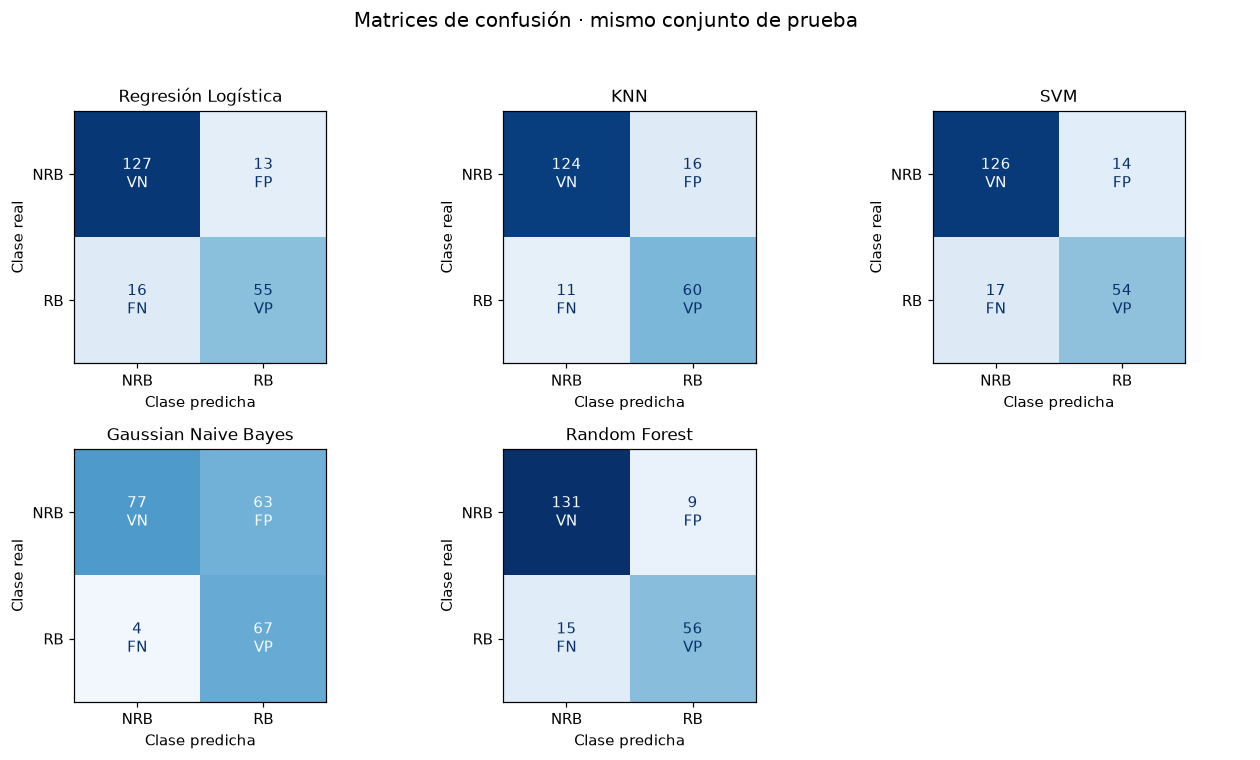

**Matriz del modelo seleccionado (SVM):** 126 NRB se clasificaron correctamente y 54 RB se identificaron correctamente. Hubo **14 falsos positivos** (NRB llamadas RB) y **17 falsos negativos** (RB llamadas NRB). Los falsos positivos atribuyen facilidad de biodegradación a sustancias que no tienen esa etiqueta experimental; los falsos negativos dejan sin reconocer sustancias RB. Sin definir costos de uso, no es posible afirmar que ambos errores tengan la misma importancia.

In [12]:
prediccion_seleccionada = predicciones_prueba[modelo_seleccionado]
matriz = confusion_matrix(y_test, prediccion_seleccionada, labels=[0, 1])
tn, fp, fn, tp = matriz.ravel()
# Se amplía la figura del modelo seleccionado sin modificar sus predicciones.
nombres_evaluacion = list(modelos_entrenados)
assert len(nombres_evaluacion) == 5
assert set(nombres_evaluacion) == set(predicciones_prueba)
assert X_test.index.equals(y_test.index)
matrices_prueba = {
    nombre_modelo: confusion_matrix(y_test, predicciones_prueba[nombre_modelo], labels=[0, 1])
    for nombre_modelo in nombres_evaluacion
}
etiquetas_celdas = np.array([["VN", "FP"], ["FN", "VP"]])
maximo_matrices = max(matriz_modelo.max() for matriz_modelo in matrices_prueba.values())
fig_matrices, ejes_matrices = plt.subplots(2, 3, figsize=(12, 7))
for eje_modelo, nombre_modelo in zip(ejes_matrices.ravel(), nombres_evaluacion):
    matriz_modelo = matrices_prueba[nombre_modelo]
    assert matriz_modelo.shape == (2, 2) and matriz_modelo.sum() == len(y_test)
    visualizacion = ConfusionMatrixDisplay(matriz_modelo, display_labels=["NRB", "RB"])
    visualizacion.plot(
        ax=eje_modelo, cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": maximo_matrices},
    )
    for fila_matriz in range(2):
        for columna_matriz in range(2):
            visualizacion.text_[fila_matriz, columna_matriz].set_text(
                f"{matriz_modelo[fila_matriz, columna_matriz]}\n"
                f"{etiquetas_celdas[fila_matriz, columna_matriz]}"
            )
    eje_modelo.set(
        title=nombre_modelo, xlabel="Clase predicha", ylabel="Clase real",
    )
ejes_matrices.ravel()[-1].set_axis_off()
fig_matrices.suptitle("Matrices de confusión · mismo conjunto de prueba", fontsize=13)
fig_matrices.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

display(Markdown(
    f"**Matriz del modelo seleccionado ({modelo_seleccionado}):** {tn} NRB se clasificaron correctamente y {tp} RB se "
    f"identificaron correctamente. Hubo **{fp} falsos positivos** (NRB llamadas RB) y "
    f"**{fn} falsos negativos** (RB llamadas NRB). "
    "Los falsos positivos atribuyen facilidad de biodegradación a sustancias que no tienen esa "
    "etiqueta experimental; los falsos negativos dejan sin reconocer sustancias RB. "
    "Sin definir costos de uso, no es posible afirmar que ambos errores tengan la misma importancia."
))

#### Interpretación conjunta de las matrices

La tabla resume los aciertos y los tipos de error en valores absolutos. Al utilizar el mismo
conjunto de prueba, estas cantidades pueden compararse directamente entre los clasificadores.

In [13]:
filas_errores = []
for nombre_modelo, matriz_modelo in matrices_prueba.items():
    vn_modelo, fp_modelo, fn_modelo, vp_modelo = matriz_modelo.ravel()
    filas_errores.append({
        "Modelo": nombre_modelo, "VN": vn_modelo, "FP": fp_modelo,
        "FN": fn_modelo, "VP": vp_modelo, "Aciertos": vn_modelo + vp_modelo,
    })
    precision_matriz = vp_modelo / (vp_modelo + fp_modelo) if vp_modelo + fp_modelo else 0.0
    recall_matriz = vp_modelo / (vp_modelo + fn_modelo) if vp_modelo + fn_modelo else 0.0
    f1_matriz = (
        2 * precision_matriz * recall_matriz / (precision_matriz + recall_matriz)
        if precision_matriz + recall_matriz else 0.0
    )
    assert np.allclose(
        [(vn_modelo + vp_modelo) / len(y_test), precision_matriz, recall_matriz, f1_matriz],
        resultados_prueba.loc[nombre_modelo].to_numpy(),
    )
resumen_matrices_prueba = pd.DataFrame(filas_errores).set_index("Modelo")
display(resumen_matrices_prueba)
modelo_mas_aciertos = resumen_matrices_prueba["Aciertos"].idxmax()
modelo_mas_fp = resumen_matrices_prueba["FP"].idxmax()
modelo_mas_fn = resumen_matrices_prueba["FN"].idxmax()
modelo_menos_fp = resumen_matrices_prueba["FP"].idxmin()
modelo_mayor_recall = resultados_prueba["Recall prueba"].idxmax()
errores_mayor_recall = resumen_matrices_prueba.loc[modelo_mayor_recall]
display(Markdown(
    f"**{modelo_mas_aciertos}** obtuvo el mayor número de aciertos "
    f"(**{resumen_matrices_prueba.loc[modelo_mas_aciertos, 'Aciertos']} de {len(y_test)}**) "
    f"y **{modelo_menos_fp}** produjo menos falsos positivos "
    f"(**{resumen_matrices_prueba.loc[modelo_menos_fp, 'FP']}**). "
    f"El mayor número de falsos positivos correspondió a **{modelo_mas_fp}** "
    f"(**{resumen_matrices_prueba.loc[modelo_mas_fp, 'FP']}**) y el de falsos negativos a "
    f"**{modelo_mas_fn}** (**{resumen_matrices_prueba.loc[modelo_mas_fn, 'FN']}**).\n\n"
    f"**{modelo_mayor_recall}** identificó más sustancias RB: "
    f"**{errores_mayor_recall['VP']} de {(y_test == 1).sum()}**, con recall "
    f"**{resultados_prueba.loc[modelo_mayor_recall, 'Recall prueba']:.4f}**. "
    f"Sin embargo, clasificó como RB **{errores_mayor_recall['FP']} sustancias NRB** "
    f"y su precision fue **{resultados_prueba.loc[modelo_mayor_recall, 'Precision prueba']:.4f}**. "
    "Se observó así un compromiso entre detectar RB y aumentar las falsas predicciones de RB. "
    "Un recall alto, por sí solo, no implica un mejor equilibrio entre ambos tipos de error."
))

,VN,FP,FN,VP,Aciertos
Modelo,,,,,
Regresión Logística,127,13,16,55,182
KNN,124,16,11,60,184
SVM,126,14,17,54,180
Gaussian Naive Bayes,77,63,4,67,144
Random Forest,131,9,15,56,187


**Random Forest** obtuvo el mayor número de aciertos (**187 de 211**) y **Random Forest** produjo menos falsos positivos (**9**). El mayor número de falsos positivos correspondió a **Gaussian Naive Bayes** (**63**) y el de falsos negativos a **SVM** (**17**).

**Gaussian Naive Bayes** identificó más sustancias RB: **67 de 71**, con recall **0.9437**. Sin embargo, clasificó como RB **63 sustancias NRB** y su precision fue **0.5154**. Se observó así un compromiso entre detectar RB y aumentar las falsas predicciones de RB. Un recall alto, por sí solo, no implica un mejor equilibrio entre ambos tipos de error.

### Curvas ROC de los cinco clasificadores

La curva ROC representa la tasa de verdaderos positivos (**TPR**, equivalente al recall de RB)
frente a la tasa de falsos positivos (**FPR**, proporción de NRB clasificadas como RB) al recorrer
los posibles umbrales de una puntuación. Este recorrido describe el comportamiento del modelo;
no cambia los umbrales de las predicciones utilizadas en las matrices.

El **AUC** resume la capacidad de distinguir RB de NRB mediante el orden de sus puntuaciones:
un valor de 1 corresponde a separación perfecta en esta muestra y 0.5 a la referencia aleatoria.
No equivale a accuracy ni demuestra que las probabilidades estén calibradas.

Se utiliza la probabilidad de RB de los modelos que ofrecen predict_proba. Para SVM se emplea
decision_function: valores mayores indican mayor tendencia hacia RB, pero no son probabilidades.
Las curvas no se calculan con las etiquetas binarias de predict.

Implementación: documentación oficial de
[roc_curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html)
y [roc_auc_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).

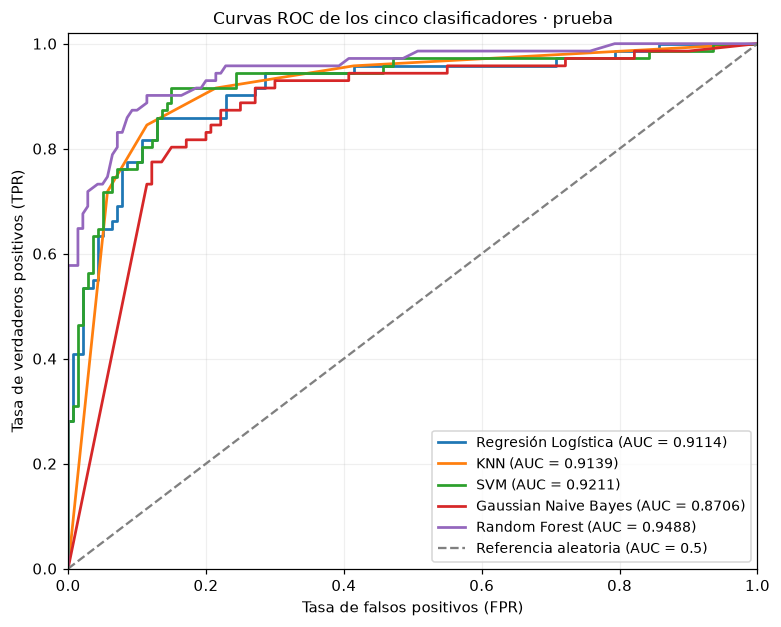

In [14]:
from sklearn.metrics import roc_curve, roc_auc_score

puntuaciones_roc = {}
origen_puntuaciones_roc = {}
curvas_roc = {}
areas_roc = {}
fig_roc, ax_roc = plt.subplots(figsize=(7.2, 5.8))
for nombre_modelo in nombres_evaluacion:
    modelo_roc = modelos_entrenados[nombre_modelo]
    assert list(modelo_roc.classes_) == [0, 1]
    if hasattr(modelo_roc, "predict_proba"):
        columna_rb = int(np.flatnonzero(modelo_roc.classes_ == 1)[0])
        puntuacion_rb = modelo_roc.predict_proba(X_test)[:, columna_rb]
        origen_puntuaciones_roc[nombre_modelo] = "predict_proba de RB"
    elif hasattr(modelo_roc, "decision_function"):
        puntuacion_rb = modelo_roc.decision_function(X_test)
        origen_puntuaciones_roc[nombre_modelo] = "decision_function hacia RB"
    else:
        raise ValueError(f"{nombre_modelo} no ofrece puntuaciones adecuadas para ROC.")
    puntuacion_rb = np.asarray(puntuacion_rb)
    assert puntuacion_rb.shape == (len(y_test),) and np.isfinite(puntuacion_rb).all()
    puntuaciones_roc[nombre_modelo] = puntuacion_rb
    fpr_modelo, tpr_modelo, _ = roc_curve(y_test, puntuacion_rb, pos_label=1)
    curvas_roc[nombre_modelo] = (fpr_modelo, tpr_modelo)
    areas_roc[nombre_modelo] = roc_auc_score(y_test, puntuacion_rb)
    ax_roc.plot(
        fpr_modelo, tpr_modelo, linewidth=1.8,
        label=f"{nombre_modelo} (AUC = {areas_roc[nombre_modelo]:.4f})",
    )
ax_roc.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referencia aleatoria (AUC = 0.5)")
ax_roc.set(
    xlim=(0, 1), ylim=(0, 1.02),
    xlabel="Tasa de falsos positivos (FPR)", ylabel="Tasa de verdaderos positivos (TPR)",
    title="Curvas ROC de los cinco clasificadores · prueba",
)
ax_roc.legend(loc="lower right", fontsize=9)
ax_roc.grid(alpha=0.2)
fig_roc.tight_layout()
plt.show()
auc_prueba = pd.Series(areas_roc, name="AUC prueba")
assert len(matrices_prueba) == len(curvas_roc) == len(auc_prueba) == 5
assert len(ax_roc.lines) == 6  # Cinco modelos y la diagonal de referencia.
assert all(0 <= valor_auc <= 1 for valor_auc in auc_prueba)

In [15]:
orden_auc = auc_prueba.sort_values(ascending=False, kind="stable")
modelo_mayor_auc = orden_auc.index[0]
segundo_modelo_auc = orden_auc.index[1]
diferencia_auc_primeros = float(orden_auc.iloc[0] - orden_auc.iloc[1])
amplitud_auc = float(orden_auc.max() - orden_auc.min())
coincidencia_roc_matrices = (
    f"El mayor AUC correspondió también a {modelo_mas_aciertos}, que obtuvo más aciertos "
    "en las matrices de confusión."
    if modelo_mayor_auc == modelo_mas_aciertos else
    f"El mayor AUC correspondió a {modelo_mayor_auc}, mientras que {modelo_mas_aciertos} "
    "obtuvo más aciertos en las matrices de confusión."
)
display(Markdown(
    f"**{modelo_mayor_auc}** obtuvo el mayor AUC (**{orden_auc.iloc[0]:.4f}**), "
    f"seguido de **{segundo_modelo_auc}** (**{orden_auc.iloc[1]:.4f}**). "
    f"La diferencia entre ambos fue **{diferencia_auc_primeros:.4f}** en una escala de 0 a 1; "
    f"los AUC de los cinco modelos abarcaron de **{orden_auc.min():.4f}** a **{orden_auc.max():.4f}**, "
    f"con una amplitud de **{amplitud_auc:.4f}**. "
    "Las diferencias entre los AUC más próximos fueron pequeñas; no permiten establecer una superioridad concluyente sin "
    "considerar la incertidumbre de esta evaluación interna.\n\n"
    f"{coincidencia_roc_matrices} El mayor recall de RB fue de **{modelo_mayor_recall}**, "
    "por lo que detectar más RB en el umbral original no implica tener el mayor AUC. "
    "La ROC resume el orden de las puntuaciones a través de varios umbrales; las matrices "
    "describen los aciertos y errores en el umbral original. Ambas perspectivas se complementan."
))

**Random Forest** obtuvo el mayor AUC (**0.9488**), seguido de **SVM** (**0.9211**). La diferencia entre ambos fue **0.0277** en una escala de 0 a 1; los AUC de los cinco modelos abarcaron de **0.8706** a **0.9488**, con una amplitud de **0.0782**. Las diferencias entre los AUC más próximos fueron pequeñas; no permiten establecer una superioridad concluyente sin considerar la incertidumbre de esta evaluación interna.

El mayor AUC correspondió también a Random Forest, que obtuvo más aciertos en las matrices de confusión. El mayor recall de RB fue de **Gaussian Naive Bayes**, por lo que detectar más RB en el umbral original no implica tener el mayor AUC. La ROC resume el orden de las puntuaciones a través de varios umbrales; las matrices describen los aciertos y errores en el umbral original. Ambas perspectivas se complementan.

### Baseline ingenuo: referencia separada de los cinco modelos

`DummyClassifier(strategy="most_frequent")` aprende únicamente cuál es la clase más
frecuente en su entrenamiento y la predice para todas las observaciones. Aunque recibe
las mismas entradas, no utiliza sus descriptores para distinguir sustancias.
No necesita escalado y **se presenta como referencia separada de los cinco modelos principales**,
sin participar en `ranking_cv`.

La referencia se evaluó con el mismo entrenamiento, el mismo objeto `validacion` y las mismas
métricas, considerando RB como clase positiva. En cada partición la clase mayoritaria se aprende solo con sus filas de
entrenamiento. Después se ajusta con todo el entrenamiento y se describe su resultado
de prueba, sin modificar la selección principal ya fijada.

Con más NRB que RB puede lograr un accuracy aparentemente aceptable mientras deja de
reconocer todas las RB. Precision se informa como cero mediante `zero_division=0`
cuando no hay predicciones positivas: no significa que haya identificado RB correctamente.

In [24]:
from sklearn.dummy import DummyClassifier

baseline_ingenuo = Pipeline([
    ("clasificador", DummyClassifier(strategy="most_frequent")),
])
puntuaciones_baseline = cross_validate(
    baseline_ingenuo, X_train, y_train, cv=validacion, scoring=metricas_cv,
    n_jobs=1, error_score="raise",
)
baseline_ingenuo.fit(X_train, y_train)
prediccion_baseline = baseline_ingenuo.predict(X_test)
resultados_baseline = pd.DataFrame({
    "Accuracy": [puntuaciones_baseline["test_accuracy"].mean(),
                 accuracy_score(y_test, prediccion_baseline)],
    "Precision RB": [puntuaciones_baseline["test_precision"].mean(),
                     precision_score(y_test, prediccion_baseline, pos_label=1, zero_division=0)],
    "Recall RB": [puntuaciones_baseline["test_recall"].mean(),
                  recall_score(y_test, prediccion_baseline, pos_label=1, zero_division=0)],
    "F1 RB": [puntuaciones_baseline["test_f1"].mean(),
              f1_score(y_test, prediccion_baseline, pos_label=1, zero_division=0)],
}, index=["Baseline · CV de entrenamiento (media)", "Baseline · prueba reservada"])
display(resultados_baseline.round(4))
matriz_baseline = confusion_matrix(y_test, prediccion_baseline, labels=[0, 1])
display(pd.DataFrame(
    matriz_baseline, index=["Real NRB", "Real RB"],
    columns=["Predicha NRB", "Predicha RB"],
))
clase_mayoritaria = int(y_train.mode().iloc[0])
nombre_mayoritaria = {0: "NRB", 1: "RB"}[clase_mayoritaria]
display(Markdown(
    f"El baseline predice siempre **{nombre_mayoritaria}**. En prueba tiene accuracy "
    f"**{resultados_baseline.iloc[1]['Accuracy']:.4f}**, pero su recall de RB es "
    f"**{resultados_baseline.iloc[1]['Recall RB']:.4f}** y su F1 de RB es "
    f"**{resultados_baseline.iloc[1]['F1 RB']:.4f}**. "
    "La comparación principal incluye los cinco clasificadores estudiados. "
    "El baseline se interpretó como referencia, sin modificar la elección del modelo."
))
assert len(modelos) == len(ranking_cv) == 5
assert np.all(prediccion_baseline == clase_mayoritaria)

,Accuracy,Precision RB,Recall RB,F1 RB
Baseline · CV de entrenamiento (media),0.6635,0.0,0.0,0.0
Baseline · prueba reservada,0.6635,0.0,0.0,0.0


,Predicha NRB,Predicha RB
Real NRB,140,0
Real RB,71,0


El baseline predice siempre **NRB**. En prueba tiene accuracy **0.6635**, pero su recall de RB es **0.0000** y su F1 de RB es **0.0000**. La comparación principal incluye los cinco clasificadores estudiados. El baseline se interpretó como referencia, sin modificar la elección del modelo.

## 10. Comparación de modelos

La tabla de la sección 9 compara rendimiento y tiempo. Esta tabla resume diferencias conceptuales:

| Modelo | Interpretabilidad y complejidad | Ventaja | Limitación |
|---|---|---|---|
| Regresión Logística | Coeficientes; frontera lineal | Relación matemática clara entre descriptores y probabilidad | No representa por sí sola todas las relaciones no lineales; coeficientes afectados por correlaciones |
| KNN | Vecinos; regla sencilla, conserva los datos | Comparación intuitiva por cercanía | Sensible a escala y variables poco útiles; predecir puede costar más que ajustar |
| SVM RBF | Frontera no lineal; interpretación global difícil | Frontera flexible con control de margen | Sensible a escala y configuración del kernel |
| Gaussian Naive Bayes | Medias, varianzas y probabilidades previas | Ajuste directo y fácil de explicar con Bayes | Normalidad e independencia condicional son aproximaciones, especialmente con conteos y presencias |
| Random Forest | Muchos árboles; interpretación global menos directa | Captura interacciones y no necesita escala | Más componentes; puede sobreajustar y no garantiza generalización química |

**Robustez observada:** la estabilidad se describió mediante la variación de F1 entre particiones,
además de considerar accuracy.
Con cinco particiones no se demuestra resistencia al ruido, a cambios de laboratorio o a nuevas
familias químicas. La rapidez tampoco se deduce solo del tiempo de ajuste: KNN, por ejemplo,
almacena los ejemplos y realiza buena parte del trabajo durante la predicción.

In [25]:
primero, segundo = ranking_cv.index[:2]
diferencia_cv = ranking_cv.loc[primero, "F1 CV"] - ranking_cv.loc[segundo, "F1 CV"]
escala_variacion = max(ranking_cv.loc[primero, "DE F1 CV"], ranking_cv.loc[segundo, "DE F1 CV"])
texto_cercania = (
    "La diferencia de medias es pequeña frente a la variación entre particiones de al menos "
    "uno de ellos; los resultados son cercanos y no demuestran una superioridad concluyente."
    if diferencia_cv <= escala_variacion else
    "La diferencia de medias supera la DE de ambos en esta división; aun así, esto no es una "
    "prueba estadística ni demuestra superioridad en otras muestras."
)
display(Markdown(
    f"En este proyecto se seleccionó **{modelo_seleccionado}** porque obtuvo el mayor F1 "
    f"medio de RB en validación cruzada. La diferencia frente a **{segundo}** fue "
    f"**{diferencia_cv:.4f}**. {texto_cercania} "
    "La selección se mantuvo según el criterio establecido; la interpretabilidad se consideró como "
    "un aspecto para interpretar el resultado, sin modificar el criterio de selección después de la prueba."
))
display(pd.DataFrame(f1_por_particion, index=[f"Partición {i}" for i in range(1, 6)]).T.round(4))

# Matiz pedagógico: interpretar la cercanía sin cambiar la regla de selección.
diferencia_svm_logistica = abs(
    resultados_cv.loc["SVM", "F1 CV"] - resultados_cv.loc["Regresión Logística", "F1 CV"]
)
lectura_empate = (
    f"SVM y Regresión Logística presentan una diferencia de F1 CV de "
    f"**{diferencia_svm_logistica:.4f}**. Los resultados se interpretan como un **empate práctico**: "
    "la diferencia es muy pequeña y no demuestra superioridad estadística concluyente. "
    "No se realizaron pruebas estadísticas ni se cambió la regla del mayor F1 medio."
)
metricas_superadas_rf = [
    metrica for metrica in resultados_prueba.columns
    if resultados_prueba.loc["Random Forest", metrica]
    > resultados_prueba.loc[modelo_seleccionado, metrica]
]
lectura_rf = (
    "En la prueba final, Random Forest obtuvo valores mayores que el seleccionado en "
    + ", ".join(metricas_superadas_rf)
    + ". Estos resultados son descriptivos y no se emplean para cambiar la selección con "
    "el conjunto de prueba."
    if metricas_superadas_rf else
    "La prueba final se interpreta de forma descriptiva y no cambia la selección "
    "efectuada con entrenamiento."
)
aclaracion_seleccion = (
    f"**{modelo_seleccionado}** se conserva como seleccionado por el mayor F1 medio "
    f"en validación cruzada. {lectura_empate} {lectura_rf}"
)
display(Markdown("**Interpretación de la comparación:** " + aclaracion_seleccion))


En este proyecto se seleccionó **SVM** porque obtuvo el mayor F1 medio de RB en validación cruzada. La diferencia frente a **Regresión Logística** fue **0.0006**. La diferencia de medias es pequeña frente a la variación entre particiones de al menos uno de ellos; los resultados son cercanos y no demuestran una superioridad concluyente. La selección se mantuvo según el criterio establecido; la interpretabilidad se consideró como un aspecto para interpretar el resultado, sin modificar el criterio de selección después de la prueba.

,Partición 1,Partición 2,Partición 3,Partición 4,Partición 5
Regresión Logística,0.8174,0.8182,0.8000,0.8073,0.8596
KNN,0.7434,0.8067,0.7458,0.8174,0.8182
SVM,0.8182,0.8381,0.7611,0.8257,0.8624
Gaussian Naive Bayes,0.6506,0.6708,0.6353,0.6923,0.6752
Random Forest,0.7963,0.7961,0.7818,0.8727,0.8073


**Interpretación de la comparación:** **SVM** se conserva como seleccionado por el mayor F1 medio en validación cruzada. SVM y Regresión Logística presentan una diferencia de F1 CV de **0.0006**. Los resultados se interpretan como un **empate práctico**: la diferencia es muy pequeña y no demuestra superioridad estadística concluyente. No se realizaron pruebas estadísticas ni se cambió la regla del mayor F1 medio. En la prueba final, Random Forest obtuvo valores mayores que el seleccionado en Accuracy prueba, Precision prueba, Recall prueba, F1 prueba. Estos resultados son descriptivos y no se emplean para cambiar la selección con el conjunto de prueba.

### Síntesis de la evaluación gráfica

La interpretación conjunta considera la discriminación descrita por ROC, los errores de las
matrices y las métricas de clasificación. El AUC de prueba es descriptivo y no sustituye el
criterio de selección basado en F1 de RB mediante validación cruzada sobre entrenamiento.

In [16]:
modelo_mayor_f1_prueba = resultados_prueba["F1 prueba"].idxmax()
metricas_seleccionado_graficas = resultados_prueba.loc[modelo_seleccionado]
display(Markdown(
    f"Se mantuvo **{modelo_seleccionado}** como modelo seleccionado por su F1 medio de RB en "
    f"validación cruzada (**{resultados_cv.loc[modelo_seleccionado, 'F1 CV']:.4f}**). "
    f"En prueba obtuvo accuracy **{metricas_seleccionado_graficas['Accuracy prueba']:.4f}**, "
    f"precision **{metricas_seleccionado_graficas['Precision prueba']:.4f}**, "
    f"recall **{metricas_seleccionado_graficas['Recall prueba']:.4f}** y "
    f"F1 **{metricas_seleccionado_graficas['F1 prueba']:.4f}**.\n\n"
    f"En la comparación descriptiva, **{modelo_mayor_f1_prueba}** obtuvo el mayor F1 de prueba "
    f"(**{resultados_prueba.loc[modelo_mayor_f1_prueba, 'F1 prueba']:.4f}**) y "
    f"**{modelo_mayor_auc}** el mayor AUC (**{auc_prueba[modelo_mayor_auc]:.4f}**). "
    f"**{modelo_mayor_recall}** detectó más RB, pero sus "
    f"**{resumen_matrices_prueba.loc[modelo_mayor_recall, 'FP']} falsos positivos** muestran "
    "por qué el recall debe interpretarse junto con precision y F1. "
    "El AUC no determina por sí solo el modelo más adecuado y la prueba no se utilizó para "
    "cambiar la selección previa ni ajustar umbrales. Las diferencias observadas se limitan "
    "a esta muestra y no demuestran superioridad universal ni generalización a nuevas familias químicas."
))
assert np.array_equal(matriz, matrices_prueba[modelo_seleccionado])
assert X_test.index.equals(y_test.index)
assert len(modelos_entrenados) == len(predicciones_prueba) == 5
print("Verificación gráfica: cinco matrices, cinco curvas ROC y métricas consistentes; selección original conservada.")

Se mantuvo **SVM** como modelo seleccionado por su F1 medio de RB en validación cruzada (**0.8211**). En prueba obtuvo accuracy **0.8531**, precision **0.7941**, recall **0.7606** y F1 **0.7770**.

En la comparación descriptiva, **Random Forest** obtuvo el mayor F1 de prueba (**0.8235**) y **Random Forest** el mayor AUC (**0.9488**). **Gaussian Naive Bayes** detectó más RB, pero sus **63 falsos positivos** muestran por qué el recall debe interpretarse junto con precision y F1. El AUC no determina por sí solo el modelo más adecuado y la prueba no se utilizó para cambiar la selección previa ni ajustar umbrales. Las diferencias observadas se limitan a esta muestra y no demuestran superioridad universal ni generalización a nuevas familias químicas.

Verificación gráfica: cinco matrices, cinco curvas ROC y métricas consistentes; selección original conservada.


## 11. Desarrollo matemático

### De la regresión lineal múltiple a la clasificación logística

#### A. Regresión lineal simple

La regresión lineal simple relaciona una entrada con una salida continua mediante una recta:

$$\widehat y=\beta_0+\beta_1x.$$

$x$ es la **variable independiente** y $\widehat y$ el **valor predicho**.
$\beta_0$ es el **intercepto** (predicción cuando $x=0$) y $\beta_1$ la
**pendiente o peso** (cambio predicho al aumentar $x$ en una unidad).

**Ejemplo inventado y exclusivamente didáctico:** la duración de un trayecto en minutos
puede representarse con $\widehat y=5+2x$, donde $x$ es la distancia en kilómetros.
Para $x=3$, la predicción es de $11$ minutos. Si una duración observada, también inventada, fuera
$y=12$, el **residuo** sería $r=y-\widehat y=1$ minuto y su cuadrado sería $1$ minuto al cuadrado.
Estos coeficientes se eligieron para explicar la ecuación; no proceden del dataset químico.

Con $m$ observaciones, el error cuadrático medio es:

$$\operatorname{MSE}=\frac{1}{m}\sum_{i=1}^{m}(y_i-\widehat y_i)^2.$$

**Mínimos cuadrados** significa buscar coeficientes que minimicen la suma de residuos al
cuadrado; minimizar su promedio, MSE, da el mismo mínimo. Elevar al cuadrado evita que
errores positivos y negativos se cancelen y penaliza más los errores grandes.

El **descenso de gradiente** es una forma iterativa de buscar ese mínimo: se calcula cómo
cambia el error con los coeficientes y se avanza en la dirección que lo reduce:

$$\boldsymbol\beta^{(t+1)}=\boldsymbol\beta^{(t)}-
\alpha\nabla_{\boldsymbol\beta}\operatorname{MSE}.$$

$t$ indica la iteración, $\alpha>0$ el tamaño del paso y $\nabla$ reúne las pendientes del
error respecto a los coeficientes, incluido el intercepto. El tamaño del paso debe ser adecuado;
uno excesivo puede impedir reducir el error. El método de mínimos cuadrados define el objetivo y el descenso
de gradiente es una manera de resolverlo; también existen métodos de álgebra lineal.
Este ejemplo tiene fines didácticos y no forma parte de la comparación de modelos.

#### B. Regresión lineal múltiple

Con $d$ variables, la predicción combina una contribución por cada entrada:

$$\widehat y=\beta_0+\sum_{j=1}^{d}\beta_jx_j.$$

Cada variable tiene un coeficiente porque su contribución puede tener dirección y magnitud
distintas. Manteniendo las otras entradas fijas, un coeficiente positivo aumenta la predicción
y uno negativo la disminuye. El intercepto se suma una sola vez.

Con variables estandarizadas $x'_j=(x_j-\bar x_{j,\mathrm{train}})/s_{j,\mathrm{train}}$,
un aumento de una unidad representa **una desviación estándar de entrenamiento**, no una
unidad original. El intercepto corresponde a entradas estandarizadas iguales a cero, es decir,
a las medias de entrenamiento; esa combinación no tiene que ser una molécula real.
Con los 41 descriptores del dataset habría 41 coeficientes, uno para cada columna, más un intercepto.

#### C. Conexión con la Regresión Logística

La variable objetivo del proyecto tiene dos clases, no una duración ni otra cantidad continua. Una combinación
lineal puede producir valores negativos o mayores que uno; no basta interpretarla como probabilidad.
Regresión Logística conserva la suma, pero la llama $z$ y aplica una sigmoide:

$$z=\beta_0+\beta_1x'_1+\cdots+\beta_{41}x'_{41},\qquad
P(Y=1\mid\mathbf X)=\frac{1}{1+e^{-z}}.$$

$Y=1$ representa RB. Las primas indican que el Pipeline utiliza las entradas
estandarizadas. La sigmoide transforma cualquier $z$ finito en una probabilidad entre cero y uno.
Con el umbral 0.5 se obtiene después una etiqueta. No es una predicción del porcentaje de
biodegradación ni una garantía experimental.

| Aspecto | Regresión Lineal | Regresión Logística del proyecto |
|---|---|---|
| Qué predice | Un número continuo | Una probabilidad de RB, convertida después en clase |
| Transformación de la suma | Se usa directamente como predicción | Se aplica la sigmoide |
| Costo habitual | MSE | Log-loss, más la regularización L2 utilizada |

La idea general de reducir un costo conecta ambos modelos, pero cambia la función que se minimiza.
Los coeficientes logísticos se estimaron mediante **L-BFGS**; el descenso de gradiente se presenta
como una explicación conceptual de la optimización. La Regresión Lineal se incluyó únicamente
como fundamento, sin ajustarla sobre etiquetas RB/NRB. A continuación se presentan los fundamentos
específicos de Regresión Logística y Gaussian Naive Bayes.

#### D. Los 41 coeficientes reales de la Regresión Logística

Los coeficientes corresponden a la Regresión Logística ajustada en la sección 8.
Se verificó que los nombres de entrada, los del escalador y los de UCI coincidieran en orden.
Así, el coeficiente en la posición $j$ corresponde exactamente a la columna $j$ que recibió
el modelo. Estos valores pertenecen solo a **Regresión Logística**.

Los coeficientes corresponden a **variables estandarizadas**. Manteniendo las otras entradas
fijas, un peso positivo aumenta las **log-odds de RB** y uno negativo las disminuye.
Las odds son $p/(1-p)$: al aumentar una variable en una desviación estándar, se multiplican
por $\exp(\beta_j)$. No se multiplica directamente la probabilidad.

La tabla completa conserva el orden original; la tabla pequeña solo ordena cinco pesos por
valor absoluto para facilitar su lectura. **No selecciona variables** ni establece importancias
universales. Los coeficientes no son porcentajes de biodegradación, no demuestran causalidad
y su interpretación individual tiene límites cuando las variables están correlacionadas.

In [26]:
# Parámetros del modelo logístico ajustado con entrenamiento.
pipeline_logistico = modelos_entrenados["Regresión Logística"]
escalador_logistico = pipeline_logistico.named_steps["escala"]
clasificador_logistico = pipeline_logistico.named_steps["clasificador"]
nombres_entrenamiento = list(pipeline_logistico.feature_names_in_)
assert nombres_entrenamiento == list(X_train.columns) == descriptores
assert list(escalador_logistico.feature_names_in_) == nombres_entrenamiento
assert clasificador_logistico.coef_.shape == (1, 41)
assert list(clasificador_logistico.classes_) == [0, 1]

coeficientes_logisticos = clasificador_logistico.coef_[0]
intercepto_logistico = float(clasificador_logistico.intercept_[0])
tabla_41_coeficientes = pd.DataFrame({
    "Posición UCI": np.arange(1, 42),
    "Coeficiente estandarizado": coeficientes_logisticos,
    "Multiplicador de odds": np.exp(coeficientes_logisticos),
}, index=pd.Index(nombres_entrenamiento, name="Descriptor"))
print("Los 41 coeficientes en el orden utilizado durante el entrenamiento:")
with pd.option_context("display.max_rows", None, "display.precision", 6):
    display(tabla_41_coeficientes)

orden_magnitud = tabla_41_coeficientes["Coeficiente estandarizado"].abs().sort_values(
    ascending=False, kind="stable",
).index
cinco_coeficientes_mayores = tabla_41_coeficientes.loc[orden_magnitud[:5]].copy()
cinco_coeficientes_mayores["Valor absoluto"] = cinco_coeficientes_mayores["Coeficiente estandarizado"].abs()
print("Cinco coeficientes de mayor magnitud, ordenados por su valor absoluto:")
display(cinco_coeficientes_mayores.round(6))
display(Markdown(fr"**Intercepto real:** $\beta_0 = {intercepto_logistico:.6f}$."))

Los 41 coeficientes en el orden utilizado durante el entrenamiento:


,Posición UCI,Coeficiente estandarizado,Multiplicador de odds
Descriptor,,,
SpMax_L,1,-0.585875,0.556619
J_Dz(e),2,-0.454960,0.634473
nHM,3,-0.486818,0.614579
F01[N-N],4,-0.333110,0.716692
F04[C-N],5,-0.617178,0.539465
NssssC,6,-1.208186,0.298739
nCb-,7,-1.376867,0.252368
C%,8,1.337331,3.808864
nCp,9,-0.259811,0.771197


Cinco coeficientes de mayor magnitud, ordenados por su valor absoluto:


,Posición UCI,Coeficiente estandarizado,Multiplicador de odds,Valor absoluto
Descriptor,,,,
nCb-,7,-1.376867,0.252368,1.376867
C%,8,1.337331,3.808864,1.337331
HyWi_B(m),13,-1.224965,0.293768,1.224965
NssssC,6,-1.208186,0.298739,1.208186
SM6_L,15,1.042925,2.837503,1.042925


**Intercepto real:** $\beta_0 = -2.350795$.

#### E. Una predicción real, paso a paso

El ejemplo corresponde a **la primera fila de `X_test`**, seleccionada independientemente
del acierto o de la probabilidad estimada.
La primera tabla muestra sus **41 entradas originales y sus 41 valores estandarizados**.
El escalador ya entrenado resta `mean_` y divide por `scale_`; nunca se ajusta a esta fila.
Para una variable constante, StandardScaler utiliza escala uno.

Se calcularon todos los términos $\beta_j x'_j$ y se sumó el intercepto para obtener $z$.
La tabla presenta las cinco contribuciones de mayor valor absoluto y agrupa la suma de las otras 36.
Un coeficiente grande puede aportar poco a esta fila si su valor estandarizado está cerca de cero:
**magnitud del coeficiente y contribución en una observación son conceptos distintos**.

La sigmoide transforma la suma en una probabilidad que se compara con 0.5 para asignar la
clase. La etiqueta real se consulta después de obtener la predicción. El cálculo se verifica
numéricamente frente a `predict_proba`. Esta explicación
corresponde a **Regresión Logística**; los otros clasificadores usan mecanismos diferentes.

In [27]:
observacion_ejemplo = X_test.iloc[[0]]
indice_ejemplo = observacion_ejemplo.index[0]
valores_originales_ejemplo = observacion_ejemplo.iloc[0].to_numpy(dtype=float)
valores_estandarizados_ejemplo = escalador_logistico.transform(observacion_ejemplo)[0]
transformacion_manual = (
    valores_originales_ejemplo - escalador_logistico.mean_
) / escalador_logistico.scale_
assert np.allclose(transformacion_manual, valores_estandarizados_ejemplo, rtol=1e-10, atol=1e-12)

tabla_entradas_ejemplo = pd.DataFrame({
    "Valor original": valores_originales_ejemplo,
    "Valor estandarizado": valores_estandarizados_ejemplo,
}, index=pd.Index(nombres_entrenamiento, name="Descriptor"))
print(f"Observación analizada: fila {indice_ejemplo + 1} del CSV original (sin encabezados).")
with pd.option_context("display.max_rows", None, "display.precision", 6):
    display(tabla_entradas_ejemplo)

contribuciones_ejemplo = pd.Series(
    coeficientes_logisticos * valores_estandarizados_ejemplo,
    index=nombres_entrenamiento, name="Contribución beta por x estandarizado",
)
mayores_contribuciones = contribuciones_ejemplo.abs().sort_values(
    ascending=False, kind="stable",
).head(5).index
tabla_contribuciones_ejemplo = pd.DataFrame({
    "Valor estandarizado": valores_estandarizados_ejemplo,
    "Coeficiente": coeficientes_logisticos,
    "Contribución": contribuciones_ejemplo.to_numpy(),
}, index=nombres_entrenamiento).loc[mayores_contribuciones]
display(tabla_contribuciones_ejemplo.round(6))

suma_cinco = float(contribuciones_ejemplo.loc[mayores_contribuciones].sum())
suma_restantes = float(contribuciones_ejemplo.drop(mayores_contribuciones).sum())
z_manual = intercepto_logistico + float(np.dot(
    coeficientes_logisticos, valores_estandarizados_ejemplo,
))
display(pd.DataFrame({
    "Valor": [intercepto_logistico, suma_cinco, suma_restantes, z_manual],
}, index=["Intercepto", "Suma de las cinco contribuciones", "Suma de las otras 36", "z total"]).round(6))
assert np.isclose(z_manual, intercepto_logistico + suma_cinco + suma_restantes)

probabilidad_manual = float(1 / (1 + np.exp(-z_manual)))
posicion_rb = int(np.flatnonzero(clasificador_logistico.classes_ == 1)[0])
probabilidad_pipeline = float(pipeline_logistico.predict_proba(observacion_ejemplo)[0, posicion_rb])
assert np.isclose(probabilidad_manual, probabilidad_pipeline, rtol=1e-10, atol=1e-12)
assert np.isclose(z_manual, pipeline_logistico.decision_function(observacion_ejemplo)[0])
prediccion_manual = int(probabilidad_manual > 0.5)
prediccion_pipeline_ejemplo = int(pipeline_logistico.predict(observacion_ejemplo)[0])
assert prediccion_manual == prediccion_pipeline_ejemplo
etiqueta_real_ejemplo = int(y_test.loc[indice_ejemplo])
nombres_clase = {0: "NRB", 1: "RB"}
display(Markdown(
    f"La suma de los 41 términos y el intercepto da **z = {z_manual:.6f}**. "
    f"La sigmoide produce **P(RB) = {probabilidad_manual:.6f}**, frente a "
    f"**{probabilidad_pipeline:.6f}** con `predict_proba`. "
    f"Al usar el umbral 0.5, se predice **{nombres_clase[prediccion_manual]}**; "
    f"la etiqueta real era **{nombres_clase[etiqueta_real_ejemplo]}**. "
    "En un empate exacto de probabilidad 0.5 se asigna NRB, como en esta implementación. "
    "El cálculo manual coincidió con el modelo, sin que la etiqueta real interviniera en su ajuste."
))

Observación analizada: fila 870 del CSV original (sin encabezados).


,Valor original,Valor estandarizado
Descriptor,,
SpMax_L,4.278,-0.920544
J_Dz(e),3.167,0.127035
nHM,0.000,-0.490295
F01[N-N],0.000,-0.157987
F04[C-N],0.000,-0.407988
NssssC,0.000,-0.270973
nCb-,0.000,-0.733483
C%,30.000,-0.764874
nCp,0.000,-0.694001


,Valor estandarizado,Coeficiente,Contribución
SdssC,-2.017349,0.563954,-1.137691
SpPosA_B(p),-1.311063,-0.835931,1.095958
C%,-0.764874,1.337331,-1.022889
nCb-,-0.733483,-1.376867,1.009909
Psi_i_A,1.549938,0.613789,0.951335


,Valor
Intercepto,-2.350795
Suma de las cinco contribuciones,0.896622
Suma de las otras 36,5.901786
z total,4.447613


La suma de los 41 términos y el intercepto da **z = 4.447613**. La sigmoide produce **P(RB) = 0.988429**, frente a **0.988429** con `predict_proba`. Al usar el umbral 0.5, se predice **RB**; la etiqueta real era **RB**. En un empate exacto de probabilidad 0.5 se asigna NRB, como en esta implementación. El cálculo manual coincidió con el modelo, sin que la etiqueta real interviniera en su ajuste.

### A. Regresión Logística

**1. Combinación lineal.** Para la sustancia $i$, con $d=41$ descriptores estandarizados:

$$z_i=\beta_0+\sum_{j=1}^{d}\beta_j x'_{ij}.$$

$x'_{ij}$ es el descriptor $j$ escalado con parámetros de entrenamiento; $\beta_j$ es su
coeficiente y $\beta_0$ es el intercepto. $z_i$ es un número real, todavía no una probabilidad.

**2. Sigmoide e interpretación de probabilidad.** La transformación logística produce:

$$p_i=\sigma(z_i)=\frac{1}{1+e^{-z_i}}\approx P(Y_i=1\mid\mathbf{x}_i).$$

$e$ es la base del logaritmo natural y $\mathbf{x}_i$ reúne los descriptores.
$p_i$ expresa la probabilidad estimada por el modelo de la etiqueta RB, no la fracción de
materia que se degradará ni una certeza experimental. Por ejemplo didáctico, si $z_i=0$,
$p_i=0.5$; si $z_i=\ln(3)$, $p_i=0.75$. No son resultados de una sustancia del archivo.

**3. Regla de clasificación.** La clasificación se realizó con el umbral predeterminado de 0.5:

$$\widehat y_i=\begin{cases}1\;(RB),&p_i>0.5,\\0\;(NRB),&p_i\leq0.5.\end{cases}$$

En empate exacto, `predict` de esta implementación devuelve la primera clase ordenada, NRB.
El umbral no se ajustó con el conjunto de prueba.

**4. Función de costo.** Con $m$ observaciones de entrenamiento y etiquetas $y_i\in\{0,1\}$,
la entropía cruzada o log-loss promedio es:

$$L(\boldsymbol\beta)=-\frac{1}{m}\sum_{i=1}^{m}
\left[y_i\ln(p_i)+(1-y_i)\ln(1-p_i)\right].$$

Si $y_i=1$, contribuye $-\ln(p_i)$: una probabilidad pequeña para una RB real recibe una
penalización grande. Si $y_i=0$, contribuye $-\ln(1-p_i)$.
Los errores cometidos con mucha confianza son especialmente costosos.

**5. Optimización y regularización.** El objetivo L2 puede expresarse conceptualmente como:

$$J(\boldsymbol\beta)=L(\boldsymbol\beta)+\frac{\lambda}{2}\sum_{j=1}^{d}\beta_j^2,
\qquad \lambda>0.$$

$\lambda$ controla cuánto se penalizan coeficientes grandes; el intercepto no se penaliza
en esta configuración. En scikit-learn, `C` controla inversamente la fuerza de la regularización
(la equivalencia numérica con $\lambda$ depende de la normalización del objetivo).
Se fijó `C=1` sin búsqueda de hiperparámetros. El optimizador **L-BFGS** actualiza los coeficientes iterativamente
utilizando información de gradientes para reducir el objetivo; no obtiene sus valores por un
simple promedio de los datos. Regularizar limita el ajuste excesivo, sin garantizar que desaparezca.

**6. Interpretación de coeficientes.** La relación con las *odds* es:

$$\ln\frac{p_i}{1-p_i}=z_i.$$

Al aumentar un descriptor en una desviación estándar de entrenamiento, manteniendo fijos los
demás, las odds se multiplican por $e^{\beta_j}$. Un signo positivo aumenta la tendencia
predicha hacia RB y uno negativo la reduce. Esto no equivale a sumar $\beta_j$ a la probabilidad.
La interpretación es condicional al modelo: no prueba causalidad y puede ser inestable cuando
varios descriptores contienen información parecida.

In [28]:
# Ejemplo real de lectura de coeficientes, sin seleccionar variables.
logistica = modelos_entrenados["Regresión Logística"].named_steps["clasificador"]
coeficientes = pd.Series(logistica.coef_[0], index=descriptores, name="Coeficiente")
tabla_coeficientes = coeficientes.loc[variables_sencillas].to_frame()
tabla_coeficientes["Multiplicador de odds por 1 DE"] = np.exp(tabla_coeficientes["Coeficiente"])
print("Coeficientes ajustados únicamente con entrenamiento:")
display(tabla_coeficientes.round(4))
print("Intercepto:", round(float(logistica.intercept_[0]), 4))

Coeficientes ajustados únicamente con entrenamiento:


,Coeficiente,Multiplicador de odds por 1 DE
nO,0.6312,1.8798
nN,-0.6670,0.5132
C%,1.3373,3.8089


Intercepto: -2.3508


### B. Gaussian Naive Bayes

**1. Teorema de Bayes.** Para la clase $c\in\{0,1\}$ y un vector de descriptores $\mathbf{x}$:

$$P(Y=c\mid\mathbf{x})=
\frac{f(\mathbf{x}\mid Y=c)P(Y=c)}{f(\mathbf{x})}.$$

$P(Y=c)$ es la **previa**: frecuencia de la clase antes de observar los descriptores.
$f(\mathbf{x}\mid Y=c)$ es la **densidad condicional** de esos valores dentro de la clase.
El resultado es una probabilidad posterior de clase; el denominador normaliza las probabilidades
y es común a todas las clases. La notación $f$ se utiliza porque, para variables continuas, una densidad no es
la probabilidad de observar exactamente un valor y puede incluso superar uno.

**2. Independencia condicional.** Naive Bayes simplifica la densidad conjunta:

$$f(\mathbf{x}\mid Y=c)\approx\prod_{j=1}^{d}f(x_j\mid Y=c).$$

Supone que, conocida la clase, cada descriptor aporta información independiente de los otros.
Así evita estimar todas sus dependencias. No significa que las variables sean independientes
en el dataset; entre descriptores moleculares pueden existir relaciones fuertes.

**3. Distribución normal.** GaussianNB aproxima cada descriptor dentro de cada clase como:

$$f(x_j\mid Y=c)=\frac{1}{\sqrt{2\pi\sigma^2_{cj}}}
\exp\left(-\frac{(x_j-\mu_{cj})^2}{2\sigma^2_{cj}}\right).$$

$\mu_{cj}$ es la media del descriptor $j$ en la clase $c$, $\sigma^2_{cj}$ su varianza y
$\pi$ la constante matemática. Valores cerca de la media suelen tener mayor densidad.
Como algunos descriptores son conteos o presencias binarias, la normalidad es una aproximación
que no representa exactamente su naturaleza; esto limita el modelo, pero no impide compararlo.

**4. Parámetros estimados con entrenamiento.** Si $n_c$ de las $m$ observaciones pertenecen a $c$:

$$\widehat P(Y=c)=\frac{n_c}{m},\qquad
\widehat\mu_{cj}=\frac{1}{n_c}\sum_{i:y_i=c}x_{ij},$$

$$\widehat\sigma^2_{cj}=\frac{1}{n_c}\sum_{i:y_i=c}(x_{ij}-\widehat\mu_{cj})^2.$$

La varianza estimada utiliza $n_c$, no $n_c-1$, porque corresponde a máxima verosimilitud
para la normal. GaussianNB añade un pequeño $\varepsilon$ de estabilidad a las varianzas;
`var_smoothing=1e-9` determina su tamaño relativo a la mayor varianza de las variables de
entrenamiento. Esto evita divisiones por cero. Este parámetro no se ajustó con el test.

**5. Regla de clasificación.** Se elige la clase con mayor puntuación posterior:

$$\widehat y=\operatorname*{arg\,max}_{c\in\{0,1\}}
\left[\ln\widehat P(Y=c)+\sum_{j=1}^{d}\ln\widehat f(x_j\mid Y=c)\right].$$

Tomar logaritmos convierte productos muy pequeños en sumas más estables y conserva el orden.
Intuitivamente se combina qué tan frecuente era cada clase con qué tan compatibles son los
descriptores observados con ella.

**Diferencia con Regresión Logística:** GaussianNB calcula normalmente previas, medias y
varianzas directamente a partir de los datos. No usa descenso de gradiente ni optimiza
iterativamente una log-loss en este ajuste. Aplica Bayes a las clases con parámetros estimados;
no construye una distribución posterior completa sobre las medias y varianzas.

In [29]:
bayes = modelos_entrenados["Gaussian Naive Bayes"].named_steps["clasificador"]
display(pd.DataFrame({
    "Clase": ["NRB" if c == 0 else "RB" for c in bayes.classes_],
    "n de entrenamiento": bayes.class_count_.astype(int),
    "Previa estimada": bayes.class_prior_,
}).set_index("Clase").round(4))
filas_parametros = []
for i, clase in enumerate(bayes.classes_):
    for variable in ["nO", "nN"]:
        j = descriptores.index(variable)
        filas_parametros.append({
            "Clase": "NRB" if clase == 0 else "RB", "Descriptor": variable,
            "Media estimada": bayes.theta_[i, j],
            "Varianza con suavizado": bayes.var_[i, j],
        })
display(pd.DataFrame(filas_parametros).round(4))
print("Epsilon añadido a las varianzas:", bayes.epsilon_)

,n de entrenamiento,Previa estimada
Clase,,
NRB,558,0.6635
RB,283,0.3365


,Clase,Descriptor,Media estimada,Varianza con suavizado
0,NRB,nO,1.5771,3.1545
1,NRB,nN,0.9050,1.4265
2,RB,nO,2.2261,3.0513
3,RB,nN,0.2686,0.3872


Epsilon añadido a las varianzas: 1.4876671624310282e-07


## 12. Resultados y discusión

La comparación resume el desempeño de los clasificadores en validación cruzada y en prueba.
Los resultados corresponden a los datos, la división y las configuraciones empleadas en este
proyecto; su interpretación se limita a estas condiciones de evaluación.

In [30]:
parrafos_resultados = []
for nombre in ranking_cv.index:
    fila = tabla_comparativa.loc[nombre]
    parrafos_resultados.append(
        f"- **{nombre}:** F1 CV {fila['F1 CV']:.4f} ± {fila['DE F1 CV']:.4f}; "
        f"en prueba, accuracy {fila['Accuracy prueba']:.4f}, precision RB {fila['Precision prueba']:.4f}, "
        f"recall RB {fila['Recall prueba']:.4f} y F1 RB {fila['F1 prueba']:.4f}."
    )
display(Markdown("\n".join(parrafos_resultados)))

fila_elegida = tabla_comparativa.loc[modelo_seleccionado]
if fp > fn:
    error_frecuente = f"Los falsos positivos fueron más frecuentes ({fp}) que los falsos negativos ({fn})."
elif fn > fp:
    error_frecuente = f"Los falsos negativos fueron más frecuentes ({fn}) que los falsos positivos ({fp})."
else:
    error_frecuente = f"Los falsos positivos y negativos aparecieron en igual número ({fp} de cada tipo)."

mejor_f1_prueba = resultados_prueba["F1 prueba"].idxmax()
lectura_prueba = (
    "También obtuvo el mayor F1 descriptivo de prueba en esta evaluación."
    if mejor_f1_prueba == modelo_seleccionado else
    f"En la tabla descriptiva, {mejor_f1_prueba} obtuvo un F1 de prueba mayor; "
    "ese resultado no modifica la selección basada en entrenamiento ni se utiliza para reajustar modelos."
)
display(Markdown(
    f"**Selección:** {modelo_seleccionado}, por F1 medio de validación cruzada "
    f"({fila_elegida['F1 CV']:.4f}). {lectura_prueba}\n\n"
    f"**Comparación:** la diferencia de F1 CV con {segundo} fue {diferencia_cv:.4f}. "
    f"{texto_cercania}\n\n"
    f"**Errores del seleccionado:** {error_frecuente} El total de errores fue "
    f"{fp + fn} de {len(y_test)} observaciones. Recall RB equivale a {tp}/{tp + fn}, "
    f"mientras que precision RB equivale a {tp}/{tp + fp}. "
    "Las frecuencias absolutas se interpretan junto con el distinto número de ejemplos de cada clase."
))

- **SVM:** F1 CV 0.8211 ± 0.0375; en prueba, accuracy 0.8531, precision RB 0.7941, recall RB 0.7606 y F1 RB 0.7770.
- **Regresión Logística:** F1 CV 0.8205 ± 0.0231; en prueba, accuracy 0.8626, precision RB 0.8088, recall RB 0.7746 y F1 RB 0.7914.
- **Random Forest:** F1 CV 0.8109 ± 0.0358; en prueba, accuracy 0.8863, precision RB 0.8615, recall RB 0.7887 y F1 RB 0.8235.
- **KNN:** F1 CV 0.7863 ± 0.0384; en prueba, accuracy 0.8720, precision RB 0.7895, recall RB 0.8451 y F1 RB 0.8163.
- **Gaussian Naive Bayes:** F1 CV 0.6648 ± 0.0222; en prueba, accuracy 0.6825, precision RB 0.5154, recall RB 0.9437 y F1 RB 0.6667.

**Selección:** SVM, por F1 medio de validación cruzada (0.8211). En la tabla descriptiva, Random Forest obtuvo un F1 de prueba mayor; ese resultado no modifica la selección basada en entrenamiento ni se utiliza para reajustar modelos.

**Comparación:** la diferencia de F1 CV con Regresión Logística fue 0.0006. La diferencia de medias es pequeña frente a la variación entre particiones de al menos uno de ellos; los resultados son cercanos y no demuestran una superioridad concluyente.

**Errores del seleccionado:** Los falsos negativos fueron más frecuentes (17) que los falsos positivos (14). El total de errores fue 31 de 211 observaciones. Recall RB equivale a 54/71, mientras que precision RB equivale a 54/68. Las frecuencias absolutas se interpretan junto con el distinto número de ejemplos de cada clase.

**Limitaciones y alcance de la interpretación:**

- El número de observaciones es limitado y existe desbalance a favor de NRB. Accuracy puede
  ocultar errores sobre RB; F1 equilibra precision y recall, pero no especifica el costo ambiental
  de cada tipo de error. No se aplicaron técnicas de corrección del desbalance.
- Los **41 descriptores se utilizaron como entradas de los modelos**, pero no identifican
  necesariamente de forma única una molécula. Dos sustancias diferentes pueden tener valores
  similares. Por ello, la división aleatoria puede incluir sustancias químicamente relacionadas
  en entrenamiento y prueba. **Esto no demuestra una fuga de información directa**: las copias
  exactas ya se eliminaron y el escalado se ajusta solo con entrenamiento. El CSV no proporciona
  suficientes identificadores estructurales para garantizar una separación por familias químicas.
  Es una **evaluación interna**, no una demostración de generalización a familias completamente nuevas.
- Los descriptores representan solo parte de la información molecular. La etiqueta no describe
  por sí sola todas las condiciones de degradación ni permite inferir tiempo o porcentaje de degradación.
- Las dependencias entre descriptores limitan la interpretación individual de coeficientes y
  el supuesto de Naive Bayes; los gráficos y parámetros no demuestran mecanismos causales.
- La variación de F1 entre particiones solo ofrece una observación de estabilidad en estos datos.
  No hubo una validación externa por laboratorio o por nuevas familias químicas.

Por esas razones, el desempeño observado no garantiza el comportamiento de sustancias
completamente diferentes ni sustituye evidencia experimental. La comparación se realizó
con configuraciones fijas para los cinco modelos.

## 13. Conclusiones

Los resultados permiten valorar el desempeño de los clasificadores y los alcances de la
predicción de biodegradabilidad a partir de descriptores moleculares.

In [31]:
display(Markdown(
    f"1. Se compararon **{len(modelos_entrenados)} clasificadores** sobre "
    f"**{len(datos)} observaciones únicas y {len(descriptores)} descriptores**, con "
    "una preparación de los datos centrada en su calidad y consistencia.\n"
    f"2. **{modelo_seleccionado}** fue seleccionado por su F1 medio de RB en validación cruzada "
    f"de **{fila_elegida['F1 CV']:.4f}**. En prueba obtuvo **F1 {fila_elegida['F1 prueba']:.4f}** "
    f"y **accuracy {fila_elegida['Accuracy prueba']:.4f}**. La selección se fijó antes de evaluar prueba.\n"
    f"3. El seleccionado cometió **{fp} falsos positivos y {fn} falsos negativos**. "
    "Estos errores y el desbalance muestran por qué es necesario acompañar accuracy con "
    "precision, recall, F1 y matriz de confusión.\n"
    "4. El análisis distinguió exploración, ajuste y evaluación, y permitió relacionar la sigmoide y "
    "la entropía cruzada con Regresión Logística, y Bayes y la distribución normal con GaussianNB.\n"
    "5. Las conclusiones son válidas para esta evaluación interna; no demuestran causalidad "
    "ni una superioridad universal. Como mejora futura, se podría comprobar el modelo "
    "en un pequeño conjunto independiente de sustancias con etiquetas verificadas, conservando "
    "este procedimiento y documentando sus errores."
))

display(Markdown("**Alcance de la selección:** " + aclaracion_seleccion))

1. Se compararon **5 clasificadores** sobre **1052 observaciones únicas y 41 descriptores**, con una preparación de los datos centrada en su calidad y consistencia.
2. **SVM** fue seleccionado por su F1 medio de RB en validación cruzada de **0.8211**. En prueba obtuvo **F1 0.7770** y **accuracy 0.8531**. La selección se fijó antes de evaluar prueba.
3. El seleccionado cometió **14 falsos positivos y 17 falsos negativos**. Estos errores y el desbalance muestran por qué es necesario acompañar accuracy con precision, recall, F1 y matriz de confusión.
4. El análisis distinguió exploración, ajuste y evaluación, y permitió relacionar la sigmoide y la entropía cruzada con Regresión Logística, y Bayes y la distribución normal con GaussianNB.
5. Las conclusiones son válidas para esta evaluación interna; no demuestran causalidad ni una superioridad universal. Como mejora futura, se podría comprobar el modelo en un pequeño conjunto independiente de sustancias con etiquetas verificadas, conservando este procedimiento y documentando sus errores.

**Alcance de la selección:** **SVM** se conserva como seleccionado por el mayor F1 medio en validación cruzada. SVM y Regresión Logística presentan una diferencia de F1 CV de **0.0006**. Los resultados se interpretan como un **empate práctico**: la diferencia es muy pequeña y no demuestra superioridad estadística concluyente. No se realizaron pruebas estadísticas ni se cambió la regla del mayor F1 medio. En la prueba final, Random Forest obtuvo valores mayores que el seleccionado en Accuracy prueba, Precision prueba, Recall prueba, F1 prueba. Estos resultados son descriptivos y no se emplean para cambiar la selección con el conjunto de prueba.

## 14. Referencias

1. Mansouri, K., Ringsted, T., Ballabio, D., Todeschini, R. y Consonni, V. (2013).
   *QSAR biodegradation* [Dataset]. UCI Machine Learning Repository.
   [Ficha, nombres ordenados de variables y referencia del artículo](https://archive.ics.uci.edu/dataset/254/qsar+biodegradation).
   [DOI del dataset: 10.24432/C5H60M](https://doi.org/10.24432/C5H60M).
2. Mansouri, K., Ringsted, T., Ballabio, D., Todeschini, R. y Consonni, V. (2013).
   *Quantitative Structure–Activity Relationship models for ready biodegradability of chemicals*.
   **Journal of Chemical Information and Modeling, 53**, 867–878.
   Referencia bibliográfica verificada en la ficha de UCI; no se consultó el texto completo del artículo
   ni se reproducen sus resultados como resultados de este proyecto.
3. Scikit-learn. [Validación cruzada](https://scikit-learn.org/stable/modules/cross_validation.html)
   y [cross_validate](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html).
4. Scikit-learn. [Regresión Logística](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
   y [fundamentos de modelos lineales](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression).
5. Scikit-learn. [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html)
   y [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html).
6. Scikit-learn. [Errores comunes y prevención de fuga de información](https://scikit-learn.org/stable/common_pitfalls.html).

7. Scikit-learn. [DummyClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html)
   y [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
8. Scikit-learn. [Mínimos cuadrados ordinarios](https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares).

Las versiones efectivamente utilizadas se muestran en la sección 4. Los enlaces corresponden
a documentación oficial; este trabajo realiza su propia comparación con el CSV local.

## 15. Guía para la exposición y el póster

**El problema en 30 segundos:** «El proyecto analiza si los descriptores de una molécula permiten
clasificarla como fácilmente biodegradable. Se compararon cinco métodos clásicos con los mismos
datos. La selección se basó en F1 de RB mediante validación cruzada y el desempeño final se evaluó
con observaciones reservadas. Los resultados apoyan el análisis, sin sustituir ensayos experimentales».

| Pregunta frecuente | Respuesta para explicar |
|---|---|
| ¿Qué son los descriptores? | Números que resumen características moleculares: conteos de átomos, grupos y estructura. Ya vienen calculados; no son nombres de sustancias. |
| ¿Por qué clasificación y no regresión? | La salida es una de dos etiquetas experimentales, RB o NRB; no una cantidad continua. |
| ¿Por qué cinco modelos? | Para comparar cinco formas clásicas de aprender con un procedimiento común, desde coeficientes y vecinos hasta Bayes y árboles. |
| ¿Qué significa la matriz de confusión? | Las filas son clases reales y las columnas predichas; la diagonal son aciertos, las otras dos celdas muestran los tipos de error. |
| ¿Cómo se eligió el modelo? | Por el F1 medio de RB en cinco particiones de entrenamiento. La tabla de prueba se calculó después. |
| ¿Qué limitaciones deben señalarse? | Desbalance, muestra limitada, posible semejanza química entre conjuntos y falta de evaluación externa; NRB no significa incapacidad absoluta de degradarse. |

La explicación del modelo seleccionado relaciona su funcionamiento con los resultados de prueba.

In [32]:
explicaciones_exposicion = {
    "Regresión Logística": "Combina los descriptores con coeficientes y transforma la suma con "
        "una sigmoide. Clasifica como RB si la probabilidad estimada supera 0.5.",
    "KNN": "Busca los cinco ejemplos más cercanos después de estandarizar los descriptores "
        "y asigna la clase que tiene mayoría entre ellos.",
    "SVM": "Traza una frontera de separación con margen amplio; el kernel RBF permite que "
        "esa frontera sea curva. Las variables se estandarizan dentro del entrenamiento.",
    "Gaussian Naive Bayes": "Combina la frecuencia previa de cada clase con la compatibilidad "
        "de los descriptores bajo distribuciones normales. Simplifica sus dependencias mediante "
        "independencia condicional.",
    "Random Forest": "Entrena 100 árboles con muestras y subconjuntos de variables aleatorios "
        "y combina sus votos para decidir la clase.",
}
display(Markdown(
    f"**Funcionamiento de {modelo_seleccionado}:** {explicaciones_exposicion[modelo_seleccionado]} "
    f"En el conjunto de prueba obtuvo F1 RB de **{fila_elegida['F1 prueba']:.3f}**, "
    f"con **{fp} falsos positivos y {fn} falsos negativos**."
))

**Funcionamiento de SVM:** Traza una frontera de separación con margen amplio; el kernel RBF permite que esa frontera sea curva. Las variables se estandarizan dentro del entrenamiento. En el conjunto de prueba obtuvo F1 RB de **0.777**, con **14 falsos positivos y 17 falsos negativos**.

**Propuesta de póster con cinco apartados:**

1. **Introducción y objetivo:** problema ambiental, pregunta y significado cuidadoso de RB/NRB.
2. **Dataset y preprocesamiento:** fuente UCI, tamaños originales y limpios, 41 descriptores,
   eliminación de copias exactas y gráfico de clases de entrenamiento.
3. **Metodología:** diagrama sencillo: `CSV → auditoría y limpieza → división 80/20 →`
   `entrenamiento y CV de 5 modelos → selección por F1 RB → prueba reservada`.
   Señalar que los escaladores se ajustan solo dentro de entrenamiento y sus particiones.
4. **Resultados:** tabla o gráfico de F1 de validación cruzada, métricas finales claramente
   identificadas como prueba y matriz de confusión del seleccionado.
5. **Conclusiones:** respuesta a la pregunta, principales errores y límites de generalización.

La exposición de Matemáticas Aplicadas puede centrarse en los fundamentos matemáticos, mientras
que la de Machine Learning puede desarrollar el procedimiento de entrenamiento y evaluación.
En ambos casos, una diferencia pequeña entre modelos no constituye una superioridad universal.

### Comprobación final de reproducibilidad

La revisión final verifica que los cinco modelos están ajustados, que las métricas corresponden
a sus predicciones y que los escaladores se estimaron solo con entrenamiento. Estas comprobaciones
no modifican los modelos ni las decisiones tomadas durante la evaluación.

In [33]:
assert len(modelos) == len(modelos_entrenados) == len(predicciones_prueba) == 5
assert modelo_seleccionado == ranking_cv.index[0]
assert X_train.shape[1] == X_test.shape[1] == 41
assert len(X_train.index.intersection(X_test.index)) == 0
for nombre, modelo in modelos_entrenados.items():
    check_is_fitted(modelo.named_steps["clasificador"])
    prediccion = predicciones_prueba[nombre]
    assert len(prediccion) == len(y_test)
    calculadas = [
        accuracy_score(y_test, prediccion),
        precision_score(y_test, prediccion, pos_label=1, zero_division=0),
        recall_score(y_test, prediccion, pos_label=1, zero_division=0),
        f1_score(y_test, prediccion, pos_label=1, zero_division=0),
    ]
    assert np.allclose(resultados_prueba.loc[nombre].to_numpy(), calculadas)
    assert np.isclose(resultados_cv.loc[nombre, "F1 CV"], np.mean(f1_por_particion[nombre]))
    if "escala" in modelo.named_steps:
        escalador = modelo.named_steps["escala"]
        assert escalador.n_samples_seen_ == len(X_train)
        assert np.allclose(escalador.mean_, X_train.mean().to_numpy())
assert matriz.sum() == len(y_test)
assert huella_original == hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
print("Verificación final correcta: cinco modelos ajustados, métricas consistentes, "
      "escalado de entrenamiento y CSV original intacto.")

# Verificaciones del baseline y de la interpretación del modelo logístico.
assert len(resultados_baseline) == 2 and matriz_baseline.sum() == len(y_test)
assert baseline_ingenuo.named_steps["clasificador"].strategy == "most_frequent"
assert len(tabla_41_coeficientes) == len(nombres_entrenamiento) == 41
assert list(tabla_41_coeficientes.index) == list(X_train.columns) == descriptores
assert np.allclose(tabla_41_coeficientes["Coeficiente estandarizado"], clasificador_logistico.coef_[0])
assert len(cinco_coeficientes_mayores) == 5
assert len(contribuciones_ejemplo) == len(tabla_entradas_ejemplo) == 41
assert np.isclose(probabilidad_manual, probabilidad_pipeline, rtol=1e-10, atol=1e-12)
print("Verificación complementaria: baseline separado, 41 coeficientes alineados y cálculo manual consistente.")


Verificación final correcta: cinco modelos ajustados, métricas consistentes, escalado de entrenamiento y CSV original intacto.
Verificación complementaria: baseline separado, 41 coeficientes alineados y cálculo manual consistente.
